# Model Score Similarity Analysis

## 模型分数相似度分析

This notebook performs model score similarity analysis to evaluate candidate replacement models against a baseline model (b046). The analysis enables data scientists to compare score distributions and identify which candidate model produces results most similar to the existing model, ensuring business continuity during model transitions.

---

## Table of Contents

1. **Setup & Configuration** - Import dependencies and configure parameters
2. **Model Loading** - Load PKL and PMML model files from disk
3. **Feature Data Loading** - Load and validate feature data for scoring
4. **Score Calculation** - Apply models to feature data and generate prediction scores
5. **Distribution Analysis** - Calculate and visualize score distributions
6. **Similarity Metrics** - Compute KS statistic, Wasserstein distance, and Jensen-Shannon divergence
7. **Model Ranking** - Rank models by similarity to reference model (b046)
8. **Final Report** - Identify and highlight the most similar model

---

## 1. Setup & Configuration

This section imports all required Python packages and defines configuration parameters. All configurable settings are centralized in a single configuration cell for easy adaptation to different datasets and models.

### Package Dependencies

- **pandas** - Data manipulation and analysis
- **numpy** - Numerical computing and array operations
- **matplotlib** - Visualization library for plots and charts
- **scipy** - Scientific computing for statistical functions (KS test, Wasserstein distance)
- **pypmml** - PMML model loading and execution
- **joblib** - Efficient serialization for sklearn models (PKL loading)

### Requirements

Install the required packages using pip:

```bash
pip install pandas numpy matplotlib scipy pypmml joblib
```

Or using requirements.txt:

```bash
pip install -r requirements.txt
```

## 2. Model Loading

This section loads machine learning model files from disk. The notebook supports both:

- **PKL files** - Python pickle/joblib serialized models (typically sklearn models)
- **PMML files** - Predictive Model Markup Language files (platform-agnostic format)

### Loading Process

1. Load exactly 4 model files from the configured directory
2. Deserialize each model using the appropriate loader
3. Wrap models in a unified interface for consistent scoring
4. Display summary of successfully loaded models
5. Handle errors gracefully - continue with remaining models if one fails

## 3. Feature Data Loading

This section loads feature data for model scoring. The data contains input variables required by models to generate predictions.

### Data Requirements

- **Format**: CSV or Parquet file
- **Content**: Feature columns matching model input requirements
- **Validation**: Check for required feature columns before scoring

### Output

- Row count, column count, and memory usage statistics
- Warning if any required features are missing

## 4. Score Calculation

This section applies each loaded model to the feature data to generate prediction scores.

### Score Types

- **Classification models**: Extract probability of positive class
- **Regression models**: Use direct prediction output

### Process

1. Validate required features exist in the data
2. Apply each model to generate predictions
3. Extract appropriate scores based on model type
4. Store scores in a structured format
5. Display summary of successful and failed scoring operations

## 5. Distribution Analysis

This section analyzes the statistical distribution of each model's scores.

### Statistics Calculated

- **Central tendency**: Mean, median (50th percentile)
- **Dispersion**: Standard deviation, min, max
- **Quantiles**: 25th, 50th, 75th percentiles
- **Histogram**: Bin counts and edges for distribution visualization
- **KDE**: Kernel density estimation for smooth distribution curves

### Visualizations

- Histogram plots for each model
- KDE overlay plots for visual comparison
- Summary statistics table

## 6. Similarity Metrics

This section computes similarity metrics between each candidate model and the reference model (b046).

### Metrics

| Metric | Description | Interpretation |
|--------|-------------|----------------|
| **KS Statistic** | Maximum distance between cumulative distribution functions | Lower = more similar |
| **Wasserstein Distance** | "Work" required to transform one distribution to another | Lower = more similar |
| **Jensen-Shannon Divergence** | Symmetric measure based on KL divergence | Lower = more similar (0 to 1) |

### Process

1. Load or calculate reference model (b046) scores
2. Compute similarity metrics for each candidate vs b046
3. Generate comparison visualizations

## 7. Model Ranking

This section ranks candidate models by their similarity to the reference model.

### Ranking Process

1. Sort models by primary similarity metric (default: Wasserstein distance)
2. Identify the model with highest similarity (lowest distance)
3. Display ranked comparison table
4. Highlight the most similar model in visualizations

### Configuration

The primary ranking metric can be configured:
- `ks` - Kolmogorov-Smirnov statistic
- `wasserstein` - Wasserstein distance (default)
- `js` - Jensen-Shannon divergence

## 8. Final Report

This section presents the final analysis results and recommendations.

### Output

- **Most Similar Model**: The candidate model with scores closest to b046
- **Similarity Metrics**: Detailed metrics for the recommended model
- **Visualizations**: Plots highlighting the recommended model vs b046
- **Summary Table**: Complete comparison of all candidate models

---

In [ ]:
# Requirements Cell - Python Package Dependencies
# ================================================
# This notebook requires the following packages:
# 
# Core Data Science:
#   - pandas: Data manipulation and analysis
#   - numpy: Numerical computing and array operations
# 
# Visualization:
#   - matplotlib: Plotting library for visualizations
# 
# Statistical Analysis:
#   - scipy: Statistical functions (KS test, Wasserstein distance)
# 
# Model Loading:
#   - pypmml: PMML model loading and execution
#   - joblib: Efficient model serialization (PKL loading)
# 
# Install via pip:
#   pip install pandas numpy matplotlib scipy pypmml joblib
# 
# Install via requirements.txt:
#   pip install -r requirements.txt
# ================================================

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

# read data

## xc

In [2]:
xc_md5 = pd.read_csv('data/260605小雨点数科95k/xyd_md5_27089_20260605电商消费变量拓展标签结果v4.csv')
xc_sha256 = pd.read_csv('data/260605小雨点数科95k/xyd_sha256_68382_20260605电商消费变量拓展标签结果v4.csv')
xc_df = pd.concat([xc_md5, xc_sha256], axis=0)
print(xc_df.shape)
xc_df.head()

(95471, 208)


,serie_no,phonenum_md5,app_date,category_order_count_30d_personalcare,first_5_months_virtual_item_count,maxAmountOfDeliverAddressArea,first_6_months_virtual_item_total_amount_percentage,first_2_months_virtual_item_amount,average_expense_amount_per_trade,deliverAddressDistinctProvinceCount,...,category_item_nunique_180d_mobile,category_order_count_30d_digital,category_order_money_180d_drug,category_order_money_180d_mobile,category_order_money_180d_personalcare,category_order_money_180d_mombaby,category_order_money_180d_digital,category_order_money_180d_home,category_order_money_180d_culture,phonenum_sha256
0,1,df021c471ed60f6735fe3bc18ea74271,20240611,NaN,NaN,2.0,NaN,NaN,19.333334,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,fa40568de5153d154d504c3127b2689e,20241215,NaN,NaN,8.0,NaN,NaN,70.188230,6.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,65.0,NaN,NaN
2,3,70ad78ec9bfdc21125a9801e7c15329c,20240912,NaN,NaN,10.0,NaN,NaN,159.221540,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,aca1e8c464467ebd7896b8c03e77f95e,20240827,NaN,NaN,7.0,NaN,NaN,99.717500,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,c874b13db1374b64ebdf559b762ca1e7,20241203,1.0,NaN,14.0,NaN,NaN,51.393333,8.0,...,NaN,NaN,NaN,NaN,8.9,NaN,NaN,NaN,8.9,NaN


In [3]:
xc_df['phonenum'] = xc_df['phonenum_md5'].fillna(xc_df['phonenum_sha256'])
xc_df.drop(columns=['phonenum_md5','phonenum_sha256'],inplace=True)
xc_df.head()

,serie_no,app_date,category_order_count_30d_personalcare,first_5_months_virtual_item_count,maxAmountOfDeliverAddressArea,first_6_months_virtual_item_total_amount_percentage,first_2_months_virtual_item_amount,average_expense_amount_per_trade,deliverAddressDistinctProvinceCount,category_item_nunique_180d_digital,...,category_item_nunique_180d_mobile,category_order_count_30d_digital,category_order_money_180d_drug,category_order_money_180d_mobile,category_order_money_180d_personalcare,category_order_money_180d_mombaby,category_order_money_180d_digital,category_order_money_180d_home,category_order_money_180d_culture,phonenum
0,1,20240611,NaN,NaN,2.0,NaN,NaN,19.333334,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,df021c471ed60f6735fe3bc18ea74271
1,2,20241215,NaN,NaN,8.0,NaN,NaN,70.188230,6.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,65.0,NaN,fa40568de5153d154d504c3127b2689e
2,3,20240912,NaN,NaN,10.0,NaN,NaN,159.221540,3.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70ad78ec9bfdc21125a9801e7c15329c
3,4,20240827,NaN,NaN,7.0,NaN,NaN,99.717500,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,aca1e8c464467ebd7896b8c03e77f95e
4,5,20241203,1.0,NaN,14.0,NaN,NaN,51.393333,8.0,NaN,...,NaN,NaN,NaN,NaN,8.9,NaN,NaN,NaN,8.9,c874b13db1374b64ebdf559b762ca1e7


## ym

In [4]:
ym_md5 = pd.read_csv('data/xyd_md5_27089_20260605.csv')
ym_sha256 = pd.read_csv('data/xyd_sha256_68382_20260605.csv')
ym_df = pd.concat([ym_md5, ym_sha256], axis=0)
print(ym_df.shape)
ym_df.head()

(95471, 8)


,serie_no,id_card_md5,phonenum_md5,app_date,code,1007384,id_card_sha256,phonenum_sha256
0,1,71890280594c3c93ef5ea2597dd18c8b,df021c471ed60f6735fe3bc18ea74271,20240611,0,0.205362,NaN,NaN
1,2,b4d8e1f68db852879c854a7a5a3796a1,fa40568de5153d154d504c3127b2689e,20241215,0,0.251021,NaN,NaN
2,3,4a8464392d0f601e40ee961abcc4f753,70ad78ec9bfdc21125a9801e7c15329c,20240912,0,0.141826,NaN,NaN
3,4,d539733cabc2ad87ea0d4c09d39e6c14,aca1e8c464467ebd7896b8c03e77f95e,20240827,0,0.276563,NaN,NaN
4,5,f6c4f750adf1e6cd881fe2a4bc530b25,c874b13db1374b64ebdf559b762ca1e7,20241203,0,0.127402,NaN,NaN


In [5]:
# ym_df 的id_card 设置为 ’id_card_md5‘和’id_card_sha256‘不为空的那个
ym_df['id_card'] = ym_df['id_card_md5'].fillna(ym_df['id_card_sha256'])
ym_df['phonenum'] = ym_df['phonenum_md5'].fillna(ym_df['phonenum_sha256'])
ym_df.head()

,serie_no,id_card_md5,phonenum_md5,app_date,code,1007384,id_card_sha256,phonenum_sha256,id_card,phonenum
0,1,71890280594c3c93ef5ea2597dd18c8b,df021c471ed60f6735fe3bc18ea74271,20240611,0,0.205362,NaN,NaN,71890280594c3c93ef5ea2597dd18c8b,df021c471ed60f6735fe3bc18ea74271
1,2,b4d8e1f68db852879c854a7a5a3796a1,fa40568de5153d154d504c3127b2689e,20241215,0,0.251021,NaN,NaN,b4d8e1f68db852879c854a7a5a3796a1,fa40568de5153d154d504c3127b2689e
2,3,4a8464392d0f601e40ee961abcc4f753,70ad78ec9bfdc21125a9801e7c15329c,20240912,0,0.141826,NaN,NaN,4a8464392d0f601e40ee961abcc4f753,70ad78ec9bfdc21125a9801e7c15329c
3,4,d539733cabc2ad87ea0d4c09d39e6c14,aca1e8c464467ebd7896b8c03e77f95e,20240827,0,0.276563,NaN,NaN,d539733cabc2ad87ea0d4c09d39e6c14,aca1e8c464467ebd7896b8c03e77f95e
4,5,f6c4f750adf1e6cd881fe2a4bc530b25,c874b13db1374b64ebdf559b762ca1e7,20241203,0,0.127402,NaN,NaN,f6c4f750adf1e6cd881fe2a4bc530b25,c874b13db1374b64ebdf559b762ca1e7


In [6]:
ym_df.drop(columns=['id_card_md5',	'phonenum_md5','id_card_sha256','phonenum_sha256'],inplace=True)
ym_df.head()

,serie_no,app_date,code,1007384,id_card,phonenum
0,1,20240611,0,0.205362,71890280594c3c93ef5ea2597dd18c8b,df021c471ed60f6735fe3bc18ea74271
1,2,20241215,0,0.251021,b4d8e1f68db852879c854a7a5a3796a1,fa40568de5153d154d504c3127b2689e
2,3,20240912,0,0.141826,4a8464392d0f601e40ee961abcc4f753,70ad78ec9bfdc21125a9801e7c15329c
3,4,20240827,0,0.276563,d539733cabc2ad87ea0d4c09d39e6c14,aca1e8c464467ebd7896b8c03e77f95e
4,5,20241203,0,0.127402,f6c4f750adf1e6cd881fe2a4bc530b25,c874b13db1374b64ebdf559b762ca1e7


# get score

In [7]:
import sys
sys.path.append('src')
from 蜜蜂分B_046部署所需.run import Predict

In [8]:
df_xc_ym = xc_df.merge(ym_df[['id_card', 'phonenum', 'app_date', '1007384']], on=['phonenum', 'app_date'], how='inner')
df_xc_ym.head()

,serie_no,app_date,category_order_count_30d_personalcare,first_5_months_virtual_item_count,maxAmountOfDeliverAddressArea,first_6_months_virtual_item_total_amount_percentage,first_2_months_virtual_item_amount,average_expense_amount_per_trade,deliverAddressDistinctProvinceCount,category_item_nunique_180d_digital,...,category_order_money_180d_drug,category_order_money_180d_mobile,category_order_money_180d_personalcare,category_order_money_180d_mombaby,category_order_money_180d_digital,category_order_money_180d_home,category_order_money_180d_culture,phonenum,id_card,1007384
0,1,20240611,NaN,NaN,2.0,NaN,NaN,19.333334,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,df021c471ed60f6735fe3bc18ea74271,71890280594c3c93ef5ea2597dd18c8b,0.205362
1,2,20241215,NaN,NaN,8.0,NaN,NaN,70.188230,6.0,NaN,...,NaN,NaN,NaN,NaN,NaN,65.0,NaN,fa40568de5153d154d504c3127b2689e,b4d8e1f68db852879c854a7a5a3796a1,0.251021
2,3,20240912,NaN,NaN,10.0,NaN,NaN,159.221540,3.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70ad78ec9bfdc21125a9801e7c15329c,4a8464392d0f601e40ee961abcc4f753,0.141826
3,4,20240827,NaN,NaN,7.0,NaN,NaN,99.717500,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,aca1e8c464467ebd7896b8c03e77f95e,d539733cabc2ad87ea0d4c09d39e6c14,0.276563
4,5,20241203,1.0,NaN,14.0,NaN,NaN,51.393333,8.0,NaN,...,NaN,NaN,8.9,NaN,NaN,NaN,8.9,c874b13db1374b64ebdf559b762ca1e7,f6c4f750adf1e6cd881fe2a4bc530b25,0.127402


In [9]:
df_xc_ym.rename(columns={'1007384':'ym_prob'},inplace=True)
predicter = Predict()
xc_probs = []
b046_probs = []
b046_scores = []
for i in range(len(df_xc_ym)):
    xc_input = df_xc_ym.loc[i].to_dict()
    xc_input.pop('phonenum')
    xc_input.pop('id_card')
    xc_input.pop('ym_prob')
    xc_input.pop('serie_no')
    xc_input.pop('app_date')
    ym_prob = df_xc_ym.loc[i,'ym_prob']
    xc_prob, b046_prob, b046_score = predicter.predict(xc_input, ym_prob)
    xc_probs.append(xc_prob)
    b046_probs.append(b046_prob)
    b046_scores.append(b046_score)

df_xc_ym['xc_prob'] = xc_probs
df_xc_ym['b046_prob'] = b046_probs
df_xc_ym['b046_score'] = b046_scores

In [10]:
df_xc_ym.head()

,serie_no,app_date,category_order_count_30d_personalcare,first_5_months_virtual_item_count,maxAmountOfDeliverAddressArea,first_6_months_virtual_item_total_amount_percentage,first_2_months_virtual_item_amount,average_expense_amount_per_trade,deliverAddressDistinctProvinceCount,category_item_nunique_180d_digital,...,category_order_money_180d_mombaby,category_order_money_180d_digital,category_order_money_180d_home,category_order_money_180d_culture,phonenum,id_card,ym_prob,xc_prob,b046_prob,b046_score
0,1,20240611,NaN,NaN,2.0,NaN,NaN,19.333334,1.0,NaN,...,NaN,NaN,NaN,NaN,df021c471ed60f6735fe3bc18ea74271,71890280594c3c93ef5ea2597dd18c8b,0.205362,0.301324,0.086409,494
1,2,20241215,NaN,NaN,8.0,NaN,NaN,70.188230,6.0,NaN,...,NaN,NaN,65.0,NaN,fa40568de5153d154d504c3127b2689e,b4d8e1f68db852879c854a7a5a3796a1,0.251021,0.038513,0.010863,677
2,3,20240912,NaN,NaN,10.0,NaN,NaN,159.221540,3.0,NaN,...,NaN,NaN,NaN,NaN,70ad78ec9bfdc21125a9801e7c15329c,4a8464392d0f601e40ee961abcc4f753,0.141826,0.178616,0.027845,596
3,4,20240827,NaN,NaN,7.0,NaN,NaN,99.717500,1.0,NaN,...,NaN,NaN,NaN,NaN,aca1e8c464467ebd7896b8c03e77f95e,d539733cabc2ad87ea0d4c09d39e6c14,0.276563,0.166135,0.061791,525
4,5,20241203,1.0,NaN,14.0,NaN,NaN,51.393333,8.0,NaN,...,NaN,NaN,NaN,8.9,c874b13db1374b64ebdf559b762ca1e7,f6c4f750adf1e6cd881fe2a4bc530b25,0.127402,0.041994,0.004807,747


In [52]:
xc_df.head()

,serie_no,phonenum_md5,app_date,category_order_count_30d_personalcare,first_5_months_virtual_item_count,maxAmountOfDeliverAddressArea,first_6_months_virtual_item_total_amount_percentage,first_2_months_virtual_item_amount,average_expense_amount_per_trade,deliverAddressDistinctProvinceCount,...,category_order_money_180d_drug,category_order_money_180d_mobile,category_order_money_180d_personalcare,category_order_money_180d_mombaby,category_order_money_180d_digital,category_order_money_180d_home,category_order_money_180d_culture,phonenum_sha256,xc_prob,phonenum
0,1,df021c471ed60f6735fe3bc18ea74271,20240611,NaN,NaN,2.0,NaN,NaN,19.333334,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.301324,df021c471ed60f6735fe3bc18ea74271
1,2,fa40568de5153d154d504c3127b2689e,20241215,NaN,NaN,8.0,NaN,NaN,70.188230,6.0,...,NaN,NaN,NaN,NaN,NaN,65.0,NaN,NaN,0.038513,fa40568de5153d154d504c3127b2689e
2,3,70ad78ec9bfdc21125a9801e7c15329c,20240912,NaN,NaN,10.0,NaN,NaN,159.221540,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.178616,70ad78ec9bfdc21125a9801e7c15329c
3,4,aca1e8c464467ebd7896b8c03e77f95e,20240827,NaN,NaN,7.0,NaN,NaN,99.717500,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.166135,aca1e8c464467ebd7896b8c03e77f95e
4,5,c874b13db1374b64ebdf559b762ca1e7,20241203,1.0,NaN,14.0,NaN,NaN,51.393333,8.0,...,NaN,NaN,8.9,NaN,NaN,NaN,8.9,NaN,0.041994,c874b13db1374b64ebdf559b762ca1e7


In [ ]:

xc_df['xc_prob'] = model.predict(xc_df[xc_feas]).iloc[:, 1].round(6)
xc_df.loc[xc_df[xc_feas].isnull().all(axis=1), 'xc_prob'] = 0
xc_df.head()

,serie_no,phonenum_md5,app_date,category_order_count_30d_personalcare,first_5_months_virtual_item_count,maxAmountOfDeliverAddressArea,first_6_months_virtual_item_total_amount_percentage,first_2_months_virtual_item_amount,average_expense_amount_per_trade,deliverAddressDistinctProvinceCount,...,category_order_count_30d_digital,category_order_money_180d_drug,category_order_money_180d_mobile,category_order_money_180d_personalcare,category_order_money_180d_mombaby,category_order_money_180d_digital,category_order_money_180d_home,category_order_money_180d_culture,phonenum_sha256,xc_prob
0,1,df021c471ed60f6735fe3bc18ea74271,20240611,NaN,NaN,2.0,NaN,NaN,19.333334,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.301324
1,2,fa40568de5153d154d504c3127b2689e,20241215,NaN,NaN,8.0,NaN,NaN,70.188230,6.0,...,NaN,NaN,NaN,NaN,NaN,NaN,65.0,NaN,NaN,0.038513
2,3,70ad78ec9bfdc21125a9801e7c15329c,20240912,NaN,NaN,10.0,NaN,NaN,159.221540,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.178616
3,4,aca1e8c464467ebd7896b8c03e77f95e,20240827,NaN,NaN,7.0,NaN,NaN,99.717500,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.166135
4,5,c874b13db1374b64ebdf559b762ca1e7,20241203,1.0,NaN,14.0,NaN,NaN,51.393333,8.0,...,NaN,NaN,NaN,8.9,NaN,NaN,NaN,8.9,NaN,0.041994


In [54]:
xc_df.head()

,serie_no,phonenum_md5,app_date,category_order_count_30d_personalcare,first_5_months_virtual_item_count,maxAmountOfDeliverAddressArea,first_6_months_virtual_item_total_amount_percentage,first_2_months_virtual_item_amount,average_expense_amount_per_trade,deliverAddressDistinctProvinceCount,...,category_order_money_180d_drug,category_order_money_180d_mobile,category_order_money_180d_personalcare,category_order_money_180d_mombaby,category_order_money_180d_digital,category_order_money_180d_home,category_order_money_180d_culture,phonenum_sha256,xc_prob,phonenum
0,1,df021c471ed60f6735fe3bc18ea74271,20240611,NaN,NaN,2.0,NaN,NaN,19.333334,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.301324,df021c471ed60f6735fe3bc18ea74271
1,2,fa40568de5153d154d504c3127b2689e,20241215,NaN,NaN,8.0,NaN,NaN,70.188230,6.0,...,NaN,NaN,NaN,NaN,NaN,65.0,NaN,NaN,0.038513,fa40568de5153d154d504c3127b2689e
2,3,70ad78ec9bfdc21125a9801e7c15329c,20240912,NaN,NaN,10.0,NaN,NaN,159.221540,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.178616,70ad78ec9bfdc21125a9801e7c15329c
3,4,aca1e8c464467ebd7896b8c03e77f95e,20240827,NaN,NaN,7.0,NaN,NaN,99.717500,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.166135,aca1e8c464467ebd7896b8c03e77f95e
4,5,c874b13db1374b64ebdf559b762ca1e7,20241203,1.0,NaN,14.0,NaN,NaN,51.393333,8.0,...,NaN,NaN,8.9,NaN,NaN,NaN,8.9,NaN,0.041994,c874b13db1374b64ebdf559b762ca1e7


In [ ]:
xc_df.drop(columns=['phonenum_md5','phonenum_sha256'],inplace=True)
df_xc_ym = xc_df.merge(ym_df[['id_card', 'phonenum', 'app_date', '1007384']], on=['phonenum', 'app_date'], how='inner')
df_xc_ym.head()

,serie_no,app_date,category_order_count_30d_personalcare,first_5_months_virtual_item_count,maxAmountOfDeliverAddressArea,first_6_months_virtual_item_total_amount_percentage,first_2_months_virtual_item_amount,average_expense_amount_per_trade,deliverAddressDistinctProvinceCount,category_item_nunique_180d_digital,...,category_order_money_180d_mobile,category_order_money_180d_personalcare,category_order_money_180d_mombaby,category_order_money_180d_digital,category_order_money_180d_home,category_order_money_180d_culture,xc_prob,phonenum,id_card,1007384
0,1,20240611,NaN,NaN,2.0,NaN,NaN,19.333334,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.301324,df021c471ed60f6735fe3bc18ea74271,71890280594c3c93ef5ea2597dd18c8b,0.205362
1,2,20241215,NaN,NaN,8.0,NaN,NaN,70.188230,6.0,NaN,...,NaN,NaN,NaN,NaN,65.0,NaN,0.038513,fa40568de5153d154d504c3127b2689e,b4d8e1f68db852879c854a7a5a3796a1,0.251021
2,3,20240912,NaN,NaN,10.0,NaN,NaN,159.221540,3.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.178616,70ad78ec9bfdc21125a9801e7c15329c,4a8464392d0f601e40ee961abcc4f753,0.141826
3,4,20240827,NaN,NaN,7.0,NaN,NaN,99.717500,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.166135,aca1e8c464467ebd7896b8c03e77f95e,d539733cabc2ad87ea0d4c09d39e6c14,0.276563
4,5,20241203,1.0,NaN,14.0,NaN,NaN,51.393333,8.0,NaN,...,NaN,8.9,NaN,NaN,NaN,8.9,0.041994,c874b13db1374b64ebdf559b762ca1e7,f6c4f750adf1e6cd881fe2a4bc530b25,0.127402


In [57]:
df_xc_ym.rename(columns={'1007384':'ym_prob'},inplace=True)

In [ ]:
xc_df['phonenum'] = xc_df['phonenum_md5'].fillna(xc_df['phonenum_sha256'])

In [15]:
ym_df.head(1)

,serie_no,id_card_md5,phonenum_md5,app_date,code,1007384,id_card_sha256,phonenum_sha256,id_card,phonenum
0,1,71890280594c3c93ef5ea2597dd18c8b,df021c471ed60f6735fe3bc18ea74271,20240611,0,0.205362,NaN,NaN,71890280594c3c93ef5ea2597dd18c8b,df021c471ed60f6735fe3bc18ea74271


In [16]:
subscores_df = ym_df[['phonenum','app_date','1007384']].merge(xc_df[['phonenum','app_date','xc_prob']],on=['phonenum','app_date'],how='inner')
subscores_df.head()

,phonenum,app_date,1007384,xc_prob
0,df021c471ed60f6735fe3bc18ea74271,20240611,0.205362,0.301324
1,fa40568de5153d154d504c3127b2689e,20241215,0.251021,0.038513
2,70ad78ec9bfdc21125a9801e7c15329c,20240912,0.141826,0.178616
3,aca1e8c464467ebd7896b8c03e77f95e,20240827,0.276563,0.166135
4,c874b13db1374b64ebdf559b762ca1e7,20241203,0.127402,0.041994


In [ ]:
subscores_df.apply(lambda x: predict(x['xc_prob'], x['1007384']), axis=1)

In [17]:
def LogitTransformation(prob):
    if 0<prob<1:
        return np.log(prob/(1-prob)), int(True)
    else:
        return 0, int(False)


def Prob2Score(prob, basePoint, PDO):
    y = np.log(prob/(1-prob))
    return basePoint+PDO/np.log(2)*(-y)


def AdjustScore(prob, min_score, max_score, basePoint, PDO):
    if prob <= 0 or prob >= 1:
        return 0

    score = Prob2Score(prob, basePoint, PDO)
    if score < min_score:
        score = min_score
    if score > max_score:
        score = max_score

    score_new = int(round((score-min_score)*600.0/(max_score - min_score) + 300,0))
    if score_new < 300:
        score_new = 300
    if score_new > 900:
        score_new = 900
    return int(score_new)
    
def predict(xc_prob, ym_prob):
    features = []
    is_valid = 0
    for fea in [xc_prob, ym_prob]:
        tmp_logit, tmp_valid = LogitTransformation(fea)
        features = features + [tmp_logit, tmp_valid]
        is_valid = max(0, tmp_valid, is_valid)
    
    #------------------- pred --------------------#
    prob = 1 / (1 + np.exp(-1 * (np.dot(np.array(features), 
                np.array([1.02633987, 1.08408293, 1.09998541, 1.43144873]))-2.52225979)))
    score = AdjustScore(prob, 810, 1830, 800, 100) * is_valid

    return score

subscores_df['score'] = subscores_df.apply(lambda x: predict(x['xc_prob'], x['1007384']), axis=1)
subscores_df.head()

,phonenum,app_date,1007384,xc_prob,score
0,df021c471ed60f6735fe3bc18ea74271,20240611,0.205362,0.301324,494
1,fa40568de5153d154d504c3127b2689e,20241215,0.251021,0.038513,677
2,70ad78ec9bfdc21125a9801e7c15329c,20240912,0.141826,0.178616,596
3,aca1e8c464467ebd7896b8c03e77f95e,20240827,0.276563,0.166135,525
4,c874b13db1374b64ebdf559b762ca1e7,20241203,0.127402,0.041994,747


In [18]:
subscores_df.to_csv('data/复现b046.csv')

## other scores 
中6-2、 中2-2、 中1

In [20]:
columns = pd.read_csv('/Users/mayongzhi/Job/Job_xyd/数据/总/2-建模样本_v7-update-合并鉴璞分V1(-1表示回溯了但返回空).csv',nrows=2).columns
print(columns)


Index(['test_id', 'id_number', 'mobile', 'apply_date', 'partner_code', 'flag',
       'enc_method', 'partner_name', 'pric_type_code', 'pric_type_desc',
       '蜜蜂分_中利率版2_2_proba', '蜜蜂分_中利率版2_2', '蜜蜂分_中利率版6_2_proba', '蜜蜂分_中利率版6_2',
       '蜜蜂分_中利率版7_2_proba', '蜜蜂分_中利率版7_2', '蜜蜂分_高利率版5_2_proba', '蜜蜂分_高利率版5_2',
       '蜜蜂分_高利率版6_2_proba', '蜜蜂分_高利率版6_2', '蜜蜂分_高利率版7_2_proba', '蜜蜂分_高利率版7_2',
       'high_sample_type', 'mid_sample_type', '1-阿里反欺诈v2标品',
       '蜜蜂分_中利率版6_3_proba', 'b058_bh_prob', 'c031_bh_prob',
       'hl_yuxin_score_v3_a', 'hl_yuxin_score_v3_b', 'hl_yuxin_score_v3_c',
       '蜜蜂分_中利率版8_1_proba_a073', '蜜蜂分_中利率版8_2_proba_a074',
       '蜜蜂分_中利率版8_3_proba_a075', 'hl_jianpu_score_v1'],
      dtype='object')


In [57]:
pd.read_csv('/Users/mayongzhi/Job/Job_xyd/数据/总/2-建模样本_v7-update-合并鉴璞分V1(-1表示回溯了但返回空).csv',nrows=2)


,test_id,id_number,mobile,apply_date,partner_code,flag,enc_method,partner_name,pric_type_code,pric_type_desc,...,蜜蜂分_中利率版6_3_proba,b058_bh_prob,c031_bh_prob,hl_yuxin_score_v3_a,hl_yuxin_score_v3_b,hl_yuxin_score_v3_c,蜜蜂分_中利率版8_1_proba_a073,蜜蜂分_中利率版8_2_proba_a074,蜜蜂分_中利率版8_3_proba_a075,hl_jianpu_score_v1
0,0,f4b49d2d8325036f6db85b596eb8e9a6,b1b38c5c0be6e133d4ad13a784a26f07,20220910,b_1,0.0,md5,数禾科技,b,中利率,...,NaN,0.108168,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,5e6a0a8ac099be089adbbe0584eeb56d,668b8dcbe724bdbf30eb68e041777c4b,20220910,b_1,0.0,md5,数禾科技,b,中利率,...,NaN,0.081587,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
other_scores_df = pd.read_csv('/Users/mayongzhi/Job/Job_xyd/数据/总/2-建模样本_v7-update-合并鉴璞分V1(-1表示回溯了但返回空).csv'
                    ,usecols=['test_id', 'id_number', 'mobile', 'apply_date','flag','enc_method', 'partner_name', 'pric_type_code', 'pric_type_desc','蜜蜂分_中利率版2_2_proba','蜜蜂分_中利率版6_2_proba','mid_sample_type'])
print(other_scores_df.shape)
other_scores_df.head()

(6332686, 12)


,test_id,id_number,mobile,apply_date,flag,enc_method,partner_name,pric_type_code,pric_type_desc,蜜蜂分_中利率版2_2_proba,蜜蜂分_中利率版6_2_proba,mid_sample_type
0,0,f4b49d2d8325036f6db85b596eb8e9a6,b1b38c5c0be6e133d4ad13a784a26f07,20220910,0.0,md5,数禾科技,b,中利率,0.090992,0.060207,1-train
1,1,5e6a0a8ac099be089adbbe0584eeb56d,668b8dcbe724bdbf30eb68e041777c4b,20220910,0.0,md5,数禾科技,b,中利率,0.077604,0.065519,1-train
2,2,a81c0001099e7ee95f48476fd199f1d4,89aacfcfa9d68e8ff2b1a2b5a779721c,20220930,0.0,md5,数禾科技,b,中利率,0.037381,0.025562,1-train
3,3,1236f3016f9b46b59b38dbe4b79c70a2,c6e84426030e452293da912e7ac0ce76,20220910,0.0,md5,数禾科技,b,中利率,0.083413,0.223740,1-train
4,4,8a9fb19b96b76f0e19988f87d9cc57cd,2d99a8c438030312d9d035b57f051662,20220924,0.0,md5,数禾科技,b,中利率,NaN,0.075078,1-train


In [12]:
df_xc_ym = df_xc_ym.merge(other_scores_df, left_on=['phonenum', 'app_date'], right_on=['mobile', 'apply_date'], how='inner')
df_xc_ym.head()

,serie_no,app_date,category_order_count_30d_personalcare,first_5_months_virtual_item_count,maxAmountOfDeliverAddressArea,first_6_months_virtual_item_total_amount_percentage,first_2_months_virtual_item_amount,average_expense_amount_per_trade,deliverAddressDistinctProvinceCount,category_item_nunique_180d_digital,...,mobile,apply_date,flag,enc_method,partner_name,pric_type_code,pric_type_desc,蜜蜂分_中利率版2_2_proba,蜜蜂分_中利率版6_2_proba,mid_sample_type
0,1,20240611,NaN,NaN,2.0,NaN,NaN,19.333334,1.0,NaN,...,df021c471ed60f6735fe3bc18ea74271,20240611,1.0,md5,weipingfubang_highirr,b,中利率,0.056795,0.089186,3-oos
1,2,20241215,NaN,NaN,8.0,NaN,NaN,70.188230,6.0,NaN,...,fa40568de5153d154d504c3127b2689e,20241215,1.0,md5,weipingfubang_highirr,b,中利率,0.041790,0.059559,3-oos
2,3,20240912,NaN,NaN,10.0,NaN,NaN,159.221540,3.0,NaN,...,70ad78ec9bfdc21125a9801e7c15329c,20240912,1.0,md5,weipingfubang_highirr,b,中利率,0.035429,0.042278,3-oos
3,4,20240827,NaN,NaN,7.0,NaN,NaN,99.717500,1.0,NaN,...,aca1e8c464467ebd7896b8c03e77f95e,20240827,1.0,md5,weipingfubang_highirr,b,中利率,0.034300,0.078568,3-oos
4,5,20241203,1.0,NaN,14.0,NaN,NaN,51.393333,8.0,NaN,...,c874b13db1374b64ebdf559b762ca1e7,20241203,1.0,md5,weipingfubang_lowerirr,b,中利率,0.038718,0.045508,2-ensemble


In [13]:
df_xc_ym.shape

(95682, 224)

In [24]:
df_all.drop_duplicates(['test_id']).shape

(95598, 11)

In [32]:
df_all = df_all.drop_duplicates(['test_id'])
df_all.drop(columns=['phonenum','app_date'],inplace=True)
df_all = df_all[['test_id','id_number',	'mobile','apply_date','flag','1007384','xc_prob','score','蜜蜂分_中利率版2_2_proba','蜜蜂分_中利率版6_2_proba']]
df_all.head()

,test_id,id_number,mobile,apply_date,flag,1007384,xc_prob,score,蜜蜂分_中利率版2_2_proba,蜜蜂分_中利率版6_2_proba
0,5585190,71890280594c3c93ef5ea2597dd18c8b,df021c471ed60f6735fe3bc18ea74271,20240611,1.0,0.205362,0.301324,494,0.056795,0.089186
1,5586534,b4d8e1f68db852879c854a7a5a3796a1,fa40568de5153d154d504c3127b2689e,20241215,1.0,0.251021,0.038513,677,0.041790,0.059559
2,5588291,4a8464392d0f601e40ee961abcc4f753,70ad78ec9bfdc21125a9801e7c15329c,20240912,1.0,0.141826,0.178616,596,0.035429,0.042278
3,5590194,d539733cabc2ad87ea0d4c09d39e6c14,aca1e8c464467ebd7896b8c03e77f95e,20240827,1.0,0.276563,0.166135,525,0.034300,0.078568
4,5893775,f6c4f750adf1e6cd881fe2a4bc530b25,c874b13db1374b64ebdf559b762ca1e7,20241203,1.0,0.127402,0.041994,747,0.038718,0.045508


In [33]:
df_all.rename(columns={'score':'b048_score'},inplace=True)
df_all.head()

,test_id,id_number,mobile,apply_date,flag,1007384,xc_prob,b048_score,蜜蜂分_中利率版2_2_proba,蜜蜂分_中利率版6_2_proba
0,5585190,71890280594c3c93ef5ea2597dd18c8b,df021c471ed60f6735fe3bc18ea74271,20240611,1.0,0.205362,0.301324,494,0.056795,0.089186
1,5586534,b4d8e1f68db852879c854a7a5a3796a1,fa40568de5153d154d504c3127b2689e,20241215,1.0,0.251021,0.038513,677,0.041790,0.059559
2,5588291,4a8464392d0f601e40ee961abcc4f753,70ad78ec9bfdc21125a9801e7c15329c,20240912,1.0,0.141826,0.178616,596,0.035429,0.042278
3,5590194,d539733cabc2ad87ea0d4c09d39e6c14,aca1e8c464467ebd7896b8c03e77f95e,20240827,1.0,0.276563,0.166135,525,0.034300,0.078568
4,5893775,f6c4f750adf1e6cd881fe2a4bc530b25,c874b13db1374b64ebdf559b762ca1e7,20241203,1.0,0.127402,0.041994,747,0.038718,0.045508


In [38]:
df_all = df_all.merge(other_scores_df[['test_id','partner_name']],on='test_id',how='inner')
df_all.drop_duplicates('test_id',inplace=True)

In [21]:
df_xc_ym.head()

,serie_no,app_date,category_order_count_30d_personalcare,first_5_months_virtual_item_count,maxAmountOfDeliverAddressArea,first_6_months_virtual_item_total_amount_percentage,first_2_months_virtual_item_amount,average_expense_amount_per_trade,deliverAddressDistinctProvinceCount,category_item_nunique_180d_digital,...,id_number,mobile,apply_date,flag,enc_method,partner_name,pric_type_code,pric_type_desc,蜜蜂分_中利率版2_2_proba,蜜蜂分_中利率版6_2_proba
0,1,20240611,NaN,NaN,2.0,NaN,NaN,19.333334,1.0,NaN,...,71890280594c3c93ef5ea2597dd18c8b,df021c471ed60f6735fe3bc18ea74271,20240611,1.0,md5,weipingfubang_highirr,b,中利率,0.056795,0.089186
1,2,20241215,NaN,NaN,8.0,NaN,NaN,70.188230,6.0,NaN,...,b4d8e1f68db852879c854a7a5a3796a1,fa40568de5153d154d504c3127b2689e,20241215,1.0,md5,weipingfubang_highirr,b,中利率,0.041790,0.059559
2,3,20240912,NaN,NaN,10.0,NaN,NaN,159.221540,3.0,NaN,...,4a8464392d0f601e40ee961abcc4f753,70ad78ec9bfdc21125a9801e7c15329c,20240912,1.0,md5,weipingfubang_highirr,b,中利率,0.035429,0.042278
3,4,20240827,NaN,NaN,7.0,NaN,NaN,99.717500,1.0,NaN,...,d539733cabc2ad87ea0d4c09d39e6c14,aca1e8c464467ebd7896b8c03e77f95e,20240827,1.0,md5,weipingfubang_highirr,b,中利率,0.034300,0.078568
4,5,20241203,1.0,NaN,14.0,NaN,NaN,51.393333,8.0,NaN,...,f6c4f750adf1e6cd881fe2a4bc530b25,c874b13db1374b64ebdf559b762ca1e7,20241203,1.0,md5,weipingfubang_lowerirr,b,中利率,0.038718,0.045508


In [14]:
from model_tools.optimization.anti_overfitting_tuner import AntiOverfittingTuner
from model_tools.evaluation.delivery_report import ModelDeliveryReport

In [15]:
model_rep = ModelDeliveryReport(df_xc_ym[df_xc_ym['ym_prob'].notnull()],'flag','ym_prob','apply_date','partner_name')
rep = model_rep.generate_model_performance()
rep

,样本类型,Good,Bad,Total,Bad_Rate,KS,AUC,TOP10_lift,PSI
0,all,57885,37483,95368,0.3930,0.1303,0.5943,1.4065,0.0000
1,weipingfubang_highirr,15318,5678,20996,0.2704,0.1046,0.5722,1.3858,0.0000
2,weipingfubang_lowerirr,4546,1391,5937,0.2343,0.1131,0.5745,1.4586,0.0000
3,hc_A2_mob3,2,5,7,0.7143,0.2000,0.4000,1.4000,0.0000
4,hc_A2_mob6,3,4,7,0.5714,0.2500,0.5000,1.7500,0.0000
5,恒昌客群A,5,2,7,0.2857,0.0000,0.0000,0.0000,0.0000
6,恒昌客群C,3,2,5,0.4000,0.5000,0.5000,2.5000,0.0000
7,hc_A1_mob3,2,2,4,0.5000,0.0000,0.0000,0.0000,0.0000
8,hc_A1_mob6,3,2,5,0.4000,0.0000,0.0000,0.0000,0.0000
9,lexin_type4,2,2,4,0.5000,0.5000,0.5000,2.0000,0.0000


In [16]:
model_rep = ModelDeliveryReport(df_xc_ym[df_xc_ym['b046_prob'].notnull()],'flag','b046_prob','apply_date','partner_name')
rep = model_rep.generate_model_performance()
rep

,样本类型,Good,Bad,Total,Bad_Rate,KS,AUC,TOP10_lift,PSI
0,all,58085,37597,95682,0.3929,0.1239,0.5819,1.4271,0.0000
1,weipingfubang_highirr,15413,5721,21134,0.2707,0.0830,0.5509,1.4067,0.0000
2,weipingfubang_lowerirr,4562,1395,5957,0.2342,0.0905,0.5529,1.4186,0.0000
3,hc_A2_mob3,2,5,7,0.7143,0.2000,0.3000,1.4000,0.0000
4,hc_A2_mob6,3,4,7,0.5714,0.2500,0.4167,1.7500,0.0000
5,恒昌客群A,5,2,7,0.2857,0.4000,0.5000,0.0000,0.0000
6,恒昌客群C,3,2,5,0.4000,0.6667,0.8333,2.5000,0.0000
7,hc_A1_mob3,2,2,4,0.5000,0.0000,0.2500,0.0000,0.0000
8,hc_A1_mob6,3,2,5,0.4000,0.0000,0.1667,0.0000,0.0000
9,lexin_type4,2,2,4,0.5000,0.5000,0.5000,2.0000,0.0000


In [17]:
model_rep = ModelDeliveryReport(df_xc_ym[df_xc_ym['xc_prob'].notnull()],'flag','xc_prob','apply_date','partner_name')
rep = model_rep.generate_model_performance()
rep

,样本类型,Good,Bad,Total,Bad_Rate,KS,AUC,TOP10_lift,PSI
0,all,58085,37597,95682,0.3929,0.0579,0.5228,1.1326,0.0000
1,weipingfubang_highirr,15413,5721,21134,0.2707,0.0446,0.5165,1.1782,0.0000
2,weipingfubang_lowerirr,4562,1395,5957,0.2342,0.0292,0.5118,1.0999,0.0000
3,hc_A2_mob3,2,5,7,0.7143,0.2000,0.2000,1.4000,0.0000
4,hc_A2_mob6,3,4,7,0.5714,0.3333,0.5000,1.7500,0.0000
5,恒昌客群A,5,2,7,0.2857,0.6000,0.7000,0.0000,0.0000
6,恒昌客群C,3,2,5,0.4000,1.0000,1.0000,2.5000,0.0000
7,hc_A1_mob3,2,2,4,0.5000,0.5000,0.7500,2.0000,0.0000
8,hc_A1_mob6,3,2,5,0.4000,0.3333,0.5000,0.0000,0.0000
9,lexin_type4,2,2,4,0.5000,0.0000,0.2500,0.0000,0.0000


In [25]:
df_xc_ym.head()

,serie_no,app_date,category_order_count_30d_personalcare,first_5_months_virtual_item_count,maxAmountOfDeliverAddressArea,first_6_months_virtual_item_total_amount_percentage,first_2_months_virtual_item_amount,average_expense_amount_per_trade,deliverAddressDistinctProvinceCount,category_item_nunique_180d_digital,...,id_number,mobile,apply_date,flag,enc_method,partner_name,pric_type_code,pric_type_desc,蜜蜂分_中利率版2_2_proba,蜜蜂分_中利率版6_2_proba
0,1,20240611,NaN,NaN,2.0,NaN,NaN,19.333334,1.0,NaN,...,71890280594c3c93ef5ea2597dd18c8b,df021c471ed60f6735fe3bc18ea74271,20240611,1.0,md5,weipingfubang_highirr,b,中利率,0.056795,0.089186
1,2,20241215,NaN,NaN,8.0,NaN,NaN,70.188230,6.0,NaN,...,b4d8e1f68db852879c854a7a5a3796a1,fa40568de5153d154d504c3127b2689e,20241215,1.0,md5,weipingfubang_highirr,b,中利率,0.041790,0.059559
2,3,20240912,NaN,NaN,10.0,NaN,NaN,159.221540,3.0,NaN,...,4a8464392d0f601e40ee961abcc4f753,70ad78ec9bfdc21125a9801e7c15329c,20240912,1.0,md5,weipingfubang_highirr,b,中利率,0.035429,0.042278
3,4,20240827,NaN,NaN,7.0,NaN,NaN,99.717500,1.0,NaN,...,d539733cabc2ad87ea0d4c09d39e6c14,aca1e8c464467ebd7896b8c03e77f95e,20240827,1.0,md5,weipingfubang_highirr,b,中利率,0.034300,0.078568
4,5,20241203,1.0,NaN,14.0,NaN,NaN,51.393333,8.0,NaN,...,f6c4f750adf1e6cd881fe2a4bc530b25,c874b13db1374b64ebdf559b762ca1e7,20241203,1.0,md5,weipingfubang_lowerirr,b,中利率,0.038718,0.045508


In [27]:
df_xc_ym.columns[-20:]

Index(['category_order_money_180d_digital', 'category_order_money_180d_home',
       'category_order_money_180d_culture', 'phonenum', 'id_card', 'ym_prob',
       'xc_prob', 'b046_prob', 'b046_score', 'test_id', 'id_number', 'mobile',
       'apply_date', 'flag', 'enc_method', 'partner_name', 'pric_type_code',
       'pric_type_desc', '蜜蜂分_中利率版2_2_proba', '蜜蜂分_中利率版6_2_proba'],
      dtype='object')

In [21]:
df_xc_ym['mid_sample_type'].value_counts()

mid_sample_type
3-oos         38144
2-ensemble    28931
1-train       28557
9-不参与标品建模        50
Name: count, dtype: int64

# 建模

## ym_prob and 蜜蜂分_中利率版6_2_proba

In [18]:
def LogitTransformation(prob):
    if 0<prob<1:
        return np.log(prob/(1-prob))
    else:
        return 0


def Prob2Score(prob, basePoint, PDO):
    y = np.log(prob/(1-prob))
    return basePoint+PDO/np.log(2)*(-y)


def AdjustScore(prob, min_score, max_score, basePoint, PDO):
    if prob <= 0 or prob >= 1:
        return 0

    score = Prob2Score(prob, basePoint, PDO)
    if score < min_score:
        score = min_score
    if score > max_score:
        score = max_score

    score_new = int(round((score-min_score)*600.0/(max_score - min_score) + 300,0))
    if score_new < 300:
        score_new = 300
    if score_new > 900:
        score_new = 900
    return int(score_new)

In [19]:
from model_tools.optimization.anti_overfitting_tuner import AntiOverfittingTuner
from sklearn.linear_model import LogisticRegression
from model_tools.optimization.objectives import KSObjective,AUCObjective

In [20]:
def get_valid_prob(x):

    if x <= 0 or x >= 1:
        y = 0
    else:
        y = 1
    return y

sub_probs = ['ym_prob','蜜蜂分_中利率版6_2_proba']
feas = []
for fea in sub_probs:
    df_xc_ym[f'{fea}_fill'] = df_xc_ym[fea].fillna(0)
    df_xc_ym[f'{fea}_valid'] = df_xc_ym[f'{fea}_fill'].apply(get_valid_prob)
    df_xc_ym[f'{fea}_trans'] = df_xc_ym[f'{fea}_fill'].apply(LogitTransformation)
    feas.append(f'{fea}_trans')
    feas.append(f'{fea}_valid')
feas

['ym_prob_trans',
 'ym_prob_valid',
 '蜜蜂分_中利率版6_2_proba_trans',
 '蜜蜂分_中利率版6_2_proba_valid']

In [ ]:
mid_sample_type
3-oos         38144
2-ensemble    28931
1-train       28557
9-不参与标品建模        50
Name: count, dtype: int64

Init signature:
AntiOverfittingTuner(
    model_class,
    model_type: str,
    direction: str = 'maximize',
    study_name: Union[str, NoneType] = None,
    max_auc_gap: float = 0.05,
    max_ks_gap: float = 0.03,
    overfitting_penalty_weight: float = 2.0,
    use_regularization_focused_space: bool = True,
    early_stopping_patience: int = 10,
)
Source:        
class AntiOverfittingTuner(HyperparameterTuner):
    """
    防过拟合超参数调优器

    核心功能:
    1. 验证集性能监控
    2. 过拟合惩罚机制
    3. 正则化导向的参数空间
    4. 早停机制
    """

    def __init__(
        self,
        model_class,
        model_type: str,
        direction: str = 'maximize',
        study_name: Optional[str] = None,
        # 防过拟合参数
        max_auc_gap: float = 0.05,
        max_ks_gap: float = 0.03,
        overfitting_penalty_weight: float = 2.0,
        use_regularization_focused_space: bool = True,
        early_stopping_patience: int = 10
    ):
        super().__init__(
            model_class=model_class,
            model_typ

In [22]:
tuner_lr = AntiOverfittingTuner(
    model_class=LogisticRegression,
    model_type='lr'
)
auc_objective = AUCObjective()

optimization_result = tuner_lr.optimize_anti_overfitting(
    X= df_xc_ym[df_xc_ym['mid_sample_type'].isin(['1-train','2-ensemble'])][feas],
    y= df_xc_ym[df_xc_ym['mid_sample_type'].isin(['1-train','2-ensemble'])]['flag'],
    objective_function=auc_objective,
    n_trials=30,  
    cv_folds=5,
    show_progress_bar=True
)

  0%|          | 0/30 [00:00<?, ?it/s]

In [40]:
optimization_result.keys()

dict_keys(['best_params', 'best_score', 'recommended_params', 'recommended_score', 'n_trials', 'performance_history', 'results_summary'])

In [23]:
pd.DataFrame(optimization_result['performance_history'])

,trial,params,train_score,val_score,final_score,train_auc,val_auc,train_ks,val_ks,auc_gap,ks_gap,is_overfitting,total_penalty,train_score_std,val_score_std,train_auc_std,val_auc_std
0,0,"{'C': 15.741890047456641, 'penalty': 'l1', 'so...",0.644788,0.644594,0.644594,0.644788,0.644594,0.211234,0.215120,0.000194,0.003885,False,0.0,0.001096,0.004343,0.001096,0.004343
1,3,"{'C': 0.0015777663630582469, 'penalty': None, ...",0.644774,0.644700,0.644700,0.644774,0.644700,0.211270,0.213766,0.000073,0.002496,False,0.0,0.000522,0.002187,0.000522,0.002187
2,5,"{'C': 0.0005397956855996448, 'penalty': 'elast...",0.644144,0.644096,0.644096,0.644144,0.644096,0.210788,0.212166,0.000048,0.001378,False,0.0,0.001443,0.005829,0.001443,0.005829
3,10,"{'C': 0.000769639183009799, 'penalty': None, '...",0.644777,0.644654,0.644654,0.644777,0.644654,0.211248,0.213059,0.000122,0.001811,False,0.0,0.000819,0.003224,0.000819,0.003224
4,11,"{'C': 0.0005350071576967551, 'penalty': None, ...",0.644776,0.644678,0.644678,0.644776,0.644678,0.211329,0.212272,0.000098,0.000943,False,0.0,0.000900,0.003603,0.000900,0.003603
5,12,"{'C': 0.008021501097987821, 'penalty': None, '...",0.644775,0.644629,0.644629,0.644775,0.644629,0.211310,0.215110,0.000146,0.003801,False,0.0,0.001191,0.004775,0.001191,0.004775
6,13,"{'C': 0.16467454850199814, 'penalty': None, 's...",0.644776,0.644694,0.644694,0.644776,0.644694,0.211236,0.212959,0.000082,0.001723,False,0.0,0.001920,0.007679,0.001920,0.007679
7,15,"{'C': 0.6189837092567543, 'penalty': 'l2', 'so...",0.644782,0.644634,0.644634,0.644782,0.644634,0.211269,0.213832,0.000148,0.002563,False,0.0,0.001337,0.005403,0.001337,0.005403
8,16,"{'C': 0.13104617587111486, 'penalty': None, 's...",0.644782,0.644685,0.644685,0.644782,0.644685,0.211446,0.213008,0.000097,0.001562,False,0.0,0.000988,0.003940,0.000988,0.003940
9,17,"{'C': 0.01811197618578836, 'penalty': None, 's...",0.644772,0.644734,0.644734,0.644772,0.644734,0.211291,0.213458,0.000038,0.002166,False,0.0,0.000297,0.001204,0.000297,0.001204


In [44]:
pd.DataFrame(optimization_result['performance_history'])['params'].to_list()

[{'C': 15.741890047456641,
  'penalty': 'l1',
  'solver': 'saga',
  'max_iter': 641,
  'random_state': 42,
  'n_jobs': -1},
 {'C': 0.0015777663630582469,
  'penalty': None,
  'solver': 'saga',
  'max_iter': 563,
  'random_state': 42,
  'n_jobs': -1},
 {'C': 0.0005397956855996448,
  'penalty': 'elasticnet',
  'solver': 'saga',
  'max_iter': 546,
  'random_state': 42,
  'l1_ratio': 0.034388521115218396,
  'n_jobs': -1},
 {'C': 0.000769639183009799,
  'penalty': None,
  'solver': 'saga',
  'max_iter': 116,
  'random_state': 42,
  'n_jobs': -1},
 {'C': 68.20019829930264,
  'penalty': 'l1',
  'solver': 'saga',
  'max_iter': 674,
  'random_state': 42,
  'n_jobs': -1},
 {'C': 90.03748409911677,
  'penalty': 'l1',
  'solver': 'saga',
  'max_iter': 863,
  'random_state': 42,
  'n_jobs': -1},
 {'C': 0.0778713991593174,
  'penalty': None,
  'solver': 'saga',
  'max_iter': 511,
  'random_state': 42,
  'n_jobs': -1},
 {'C': 0.1285153472360622,
  'penalty': 'l2',
  'solver': 'saga',
  'max_iter': 77

In [24]:
candidate_parmas = pd.DataFrame(optimization_result['performance_history'])['params'].to_list()


In [26]:
from model_tools.optimization.experiment_pipeline import run_experiment_batch
run_experiment_batch??

Signature:
run_experiment_batch(
    model_class: 'Any',
    train_data: 'pd.DataFrame',
    oot_data: 'pd.DataFrame',
    feature_cols: 'Sequence[str]',
    target_col: 'str',
    candidate_params: 'List[Dict[str, Any]]',
    report_dir: 'Union[str, Path]',
    ledger_path: 'Union[str, Path]',
    study_name: 'str' = 'anti_overfitting',
    score_col: 'str' = 'score',
    sample_type_col: 'str' = 'sample_type',
    date_col: 'str' = 'date',
    report_features: 'Optional[List[str]]' = None,
    report_feature_names: 'Optional[Dict[str, str]]' = None,
    bin_method: 'str' = 'quantile',
    importance_type: 'str' = 'gain',
) -> 'pd.DataFrame'
Source:   
def run_experiment_batch(
    model_class: Any,
    train_data: pd.DataFrame,
    oot_data: pd.DataFrame,
    feature_cols: Sequence[str],
    target_col: str,
    candidate_params: List[Dict[str, Any]],
    report_dir: Union[str, Path],
    ledger_path: Union[str, Path],
    study_name: str = "anti_overfitting",
    score_col: str = "s

In [27]:
df_xc_ym.head()

,serie_no,app_date,category_order_count_30d_personalcare,first_5_months_virtual_item_count,maxAmountOfDeliverAddressArea,first_6_months_virtual_item_total_amount_percentage,first_2_months_virtual_item_amount,average_expense_amount_per_trade,deliverAddressDistinctProvinceCount,category_item_nunique_180d_digital,...,pric_type_desc,蜜蜂分_中利率版2_2_proba,蜜蜂分_中利率版6_2_proba,mid_sample_type,ym_prob_fill,ym_prob_valid,ym_prob_trans,蜜蜂分_中利率版6_2_proba_fill,蜜蜂分_中利率版6_2_proba_valid,蜜蜂分_中利率版6_2_proba_trans
0,1,20240611,NaN,NaN,2.0,NaN,NaN,19.333334,1.0,NaN,...,中利率,0.056795,0.089186,3-oos,0.205362,1,-1.353112,0.089186,1,-2.323618
1,2,20241215,NaN,NaN,8.0,NaN,NaN,70.188230,6.0,NaN,...,中利率,0.041790,0.059559,3-oos,0.251021,1,-1.093174,0.059559,1,-2.759382
2,3,20240912,NaN,NaN,10.0,NaN,NaN,159.221540,3.0,NaN,...,中利率,0.035429,0.042278,3-oos,0.141826,1,-1.800206,0.042278,1,-3.120289
3,4,20240827,NaN,NaN,7.0,NaN,NaN,99.717500,1.0,NaN,...,中利率,0.034300,0.078568,3-oos,0.276563,1,-0.961575,0.078568,1,-2.461959
4,5,20241203,1.0,NaN,14.0,NaN,NaN,51.393333,8.0,NaN,...,中利率,0.038718,0.045508,2-ensemble,0.127402,1,-1.924128,0.045508,1,-3.043295


✓ 样本情况统计完成
✓ 模型效果分析完成
✓ 模型效果分箱分析完成
✗ 评估指标报告生成失败: 'cum_good_rate'
✓ TOP10变量有效性分析完成
✓ 变量有效性按月拆分分析完成
✓ TOP10变量稳定性分析完成
✓ 单特征时间分布分析完成
✓ 模型分表现分析完成
✓ 报告已保存至: report/anti_overfitting-t0-20260608092127-c07790a5.xlsx
✓ 样本情况统计完成
✓ 模型效果分析完成
✓ 模型效果分箱分析完成
✗ 评估指标报告生成失败: 'cum_good_rate'
✓ TOP10变量有效性分析完成
✓ 变量有效性按月拆分分析完成
✓ TOP10变量稳定性分析完成
✓ 单特征时间分布分析完成
✓ 模型分表现分析完成
✓ 报告已保存至: report/anti_overfitting-t1-20260608092130-fb7ae32c.xlsx
✓ 样本情况统计完成
✓ 模型效果分析完成
✓ 模型效果分箱分析完成
✗ 评估指标报告生成失败: 'cum_good_rate'
✓ TOP10变量有效性分析完成
✓ 变量有效性按月拆分分析完成
✓ TOP10变量稳定性分析完成
✓ 单特征时间分布分析完成
✓ 模型分表现分析完成
✓ 报告已保存至: report/anti_overfitting-t2-20260608092131-f4b0ba99.xlsx
✓ 样本情况统计完成
✓ 模型效果分析完成
✓ 模型效果分箱分析完成
✗ 评估指标报告生成失败: 'cum_good_rate'
✓ TOP10变量有效性分析完成
✓ 变量有效性按月拆分分析完成
✓ TOP10变量稳定性分析完成
✓ 单特征时间分布分析完成
✓ 模型分表现分析完成
✓ 报告已保存至: report/anti_overfitting-t3-20260608092133-7eee65f6.xlsx
✓ 样本情况统计完成
✓ 模型效果分析完成
✓ 模型效果分箱分析完成
✗ 评估指标报告生成失败: 'cum_good_rate'
✓ TOP10变量有效性分析完成
✓ 变量有效性按月拆分分析完成
✓ TOP10变量稳定性分析完成
✓ 单特征时间分布分析完成
✓ 模型分表现分析完成
✓ 报告已保存至: report/anti_overfitti

,experiment_id,trial,params_json,params_hash,train_metric,val_metric,oot_auc,oot_ks,report_path,created_at
0,anti_overfitting-t0-20260608092127-c07790a5,0,"{""C"":15.741890047456641,""max_iter"":641,""n_jobs...",c07790a556c1885fb6e5114c5c41c5d3,0.0,0.0,0.652651,0.221227,report/anti_overfitting-t0-20260608092127-c077...,2026-06-08 09:21:27
1,anti_overfitting-t1-20260608092130-fb7ae32c,1,"{""C"":0.0015777663630582469,""max_iter"":563,""n_j...",fb7ae32c7b9625628389f434c57ef776,0.0,0.0,0.652650,0.221227,report/anti_overfitting-t1-20260608092130-fb7a...,2026-06-08 09:21:27
2,anti_overfitting-t2-20260608092131-f4b0ba99,2,"{""C"":0.0005397956855996448,""l1_ratio"":0.034388...",f4b0ba991d587dbae85d72e4a75eb2bc,0.0,0.0,0.650118,0.217630,report/anti_overfitting-t2-20260608092131-f4b0...,2026-06-08 09:21:27
3,anti_overfitting-t3-20260608092133-7eee65f6,3,"{""C"":0.000769639183009799,""max_iter"":116,""n_jo...",7eee65f6b82f1a23f9d3731c4c9380f7,0.0,0.0,0.652650,0.221227,report/anti_overfitting-t3-20260608092133-7eee...,2026-06-08 09:21:27
4,anti_overfitting-t4-20260608092135-9cea1e8f,4,"{""C"":0.0005350071576967551,""max_iter"":137,""n_j...",9cea1e8ff0eb6864001615ca993981c4,0.0,0.0,0.652650,0.221227,report/anti_overfitting-t4-20260608092135-9cea...,2026-06-08 09:21:27
5,anti_overfitting-t5-20260608092136-e7913c08,5,"{""C"":0.008021501097987821,""max_iter"":290,""n_jo...",e7913c0841e71d10a3feeba6d0bc6e5f,0.0,0.0,0.652650,0.221227,report/anti_overfitting-t5-20260608092136-e791...,2026-06-08 09:21:27
6,anti_overfitting-t6-20260608092138-b4814a40,6,"{""C"":0.16467454850199814,""max_iter"":942,""n_job...",b4814a40c60a7860806258e47b00c7d9,0.0,0.0,0.652650,0.221227,report/anti_overfitting-t6-20260608092138-b481...,2026-06-08 09:21:27
7,anti_overfitting-t7-20260608092140-e9c8ba90,7,"{""C"":0.6189837092567543,""max_iter"":936,""n_jobs...",e9c8ba909c6b034fb46ec46f32b98d6f,0.0,0.0,0.652649,0.221261,report/anti_overfitting-t7-20260608092140-e9c8...,2026-06-08 09:21:27
8,anti_overfitting-t8-20260608092142-b823cc1a,8,"{""C"":0.13104617587111486,""max_iter"":987,""n_job...",b823cc1a4cc62eadac6e0561b131338d,0.0,0.0,0.652650,0.221227,report/anti_overfitting-t8-20260608092142-b823...,2026-06-08 09:21:27
9,anti_overfitting-t9-20260608092143-ef0a63e9,9,"{""C"":0.01811197618578836,""max_iter"":695,""n_job...",ef0a63e95af16bbcf4505e82cfbd8cac,0.0,0.0,0.652650,0.221227,report/anti_overfitting-t9-20260608092143-ef0a...,2026-06-08 09:21:27


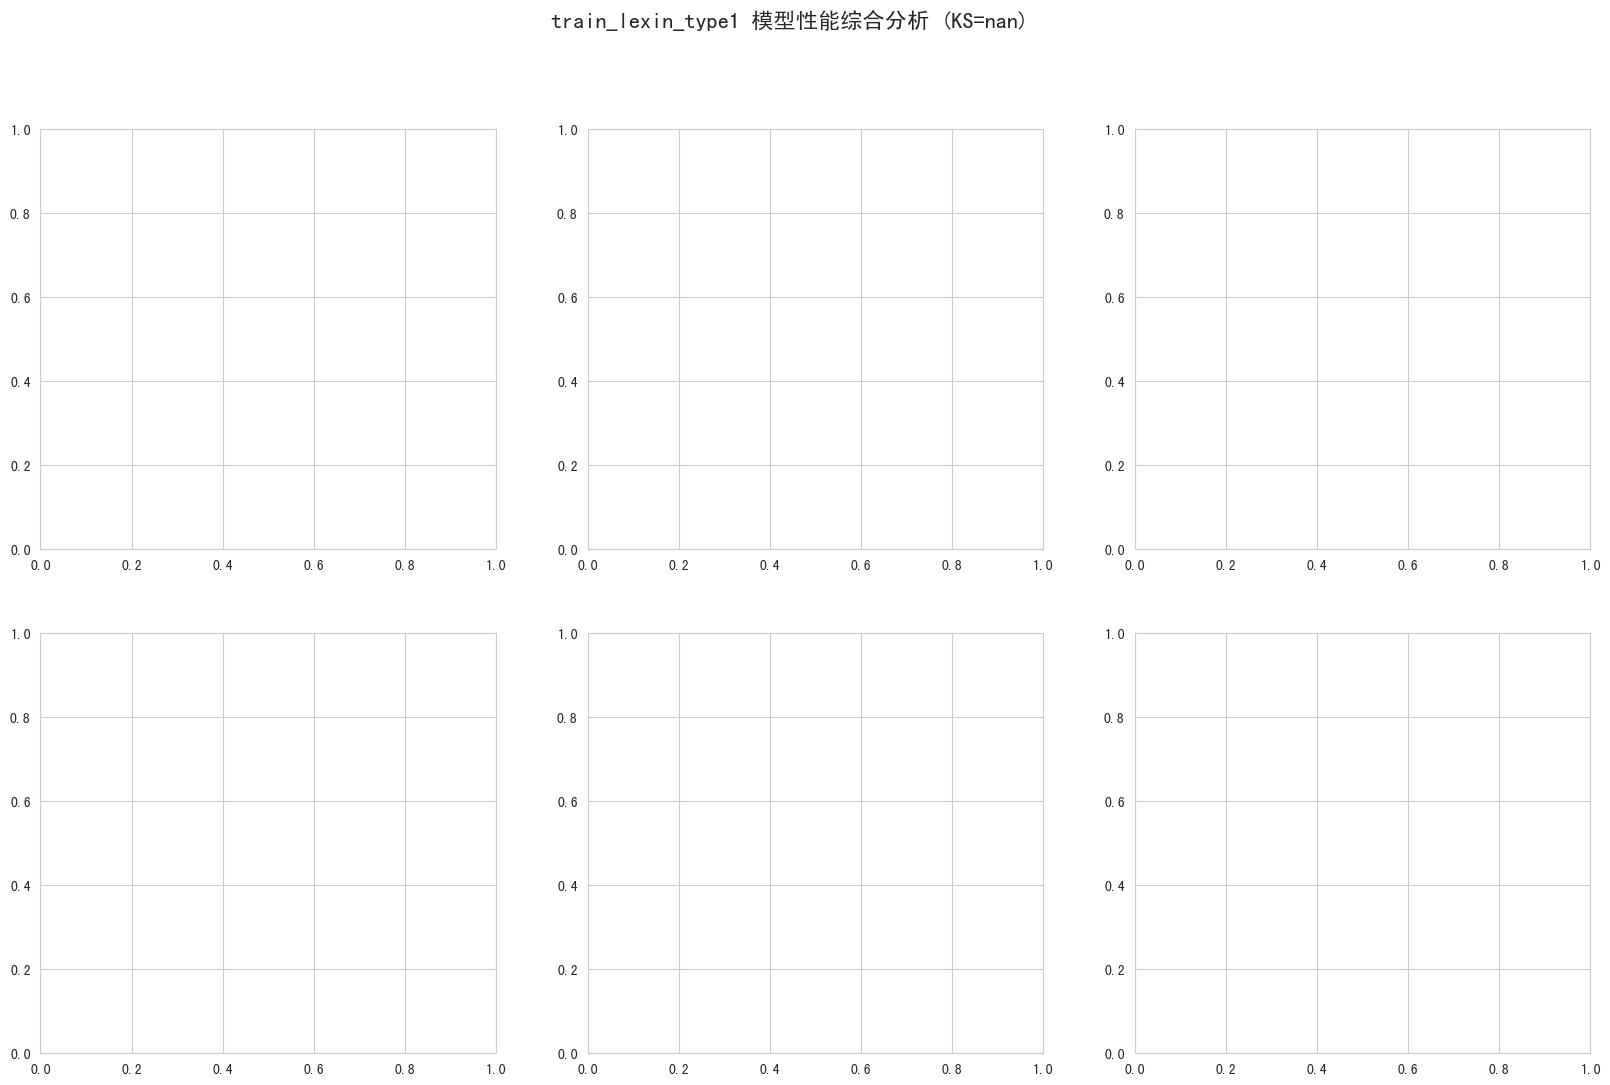

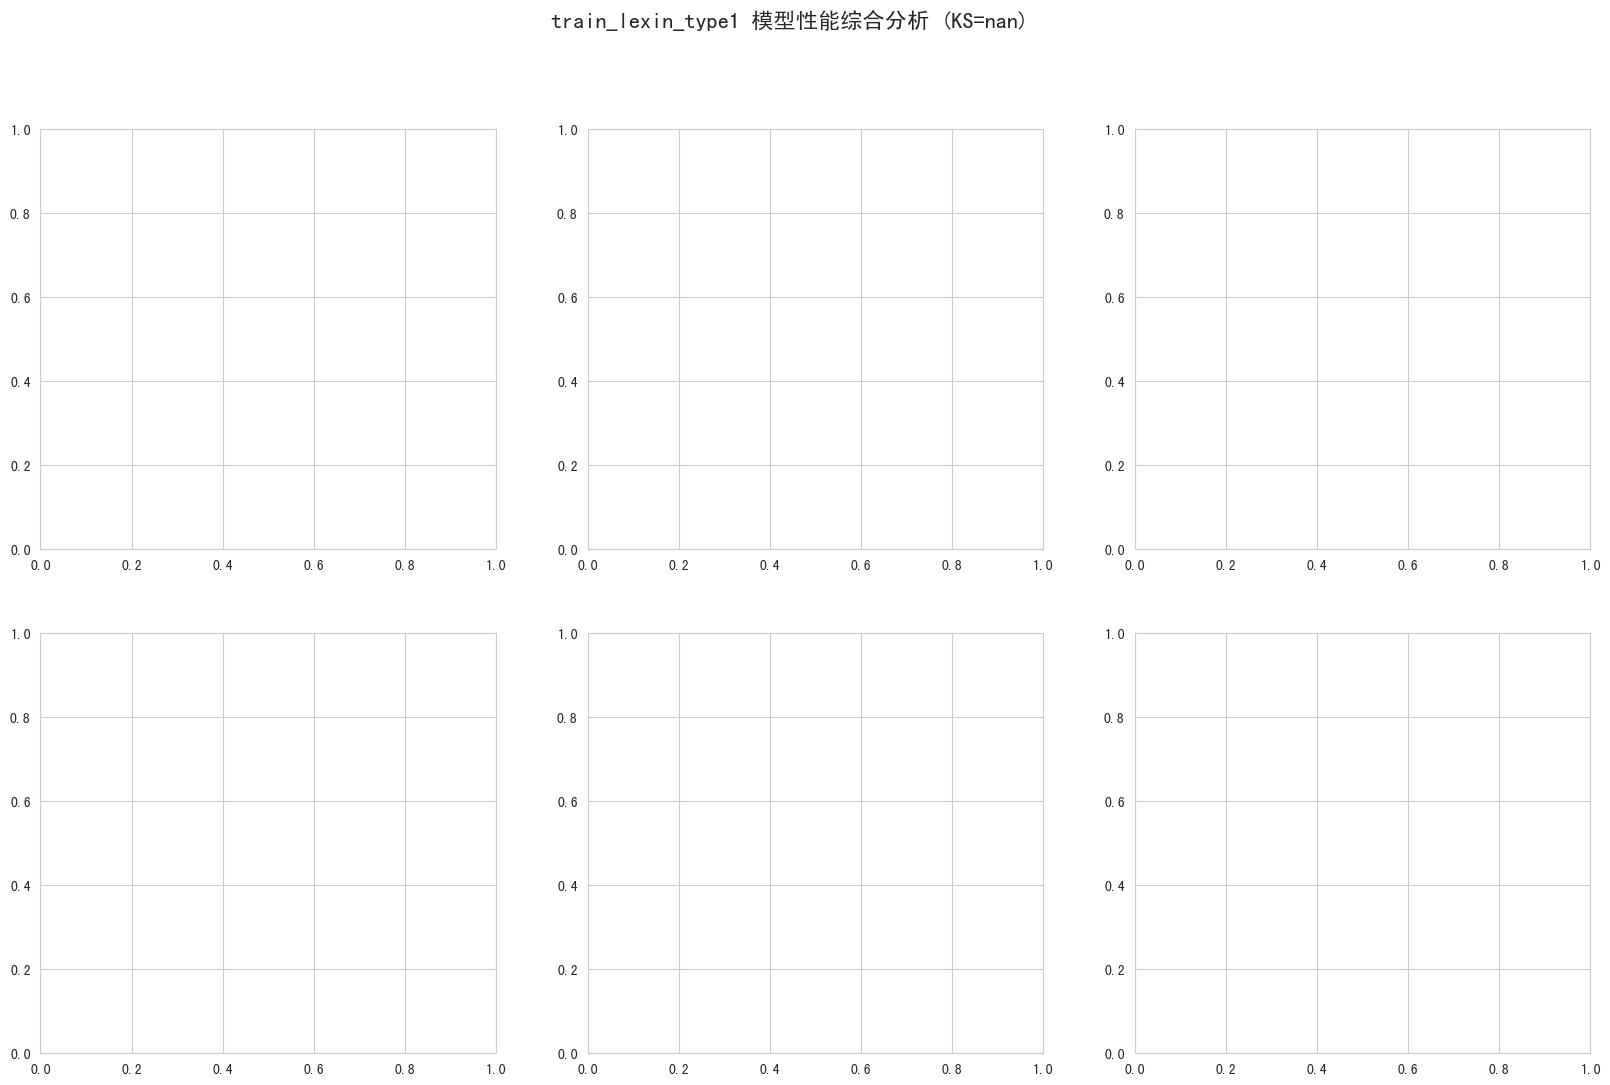

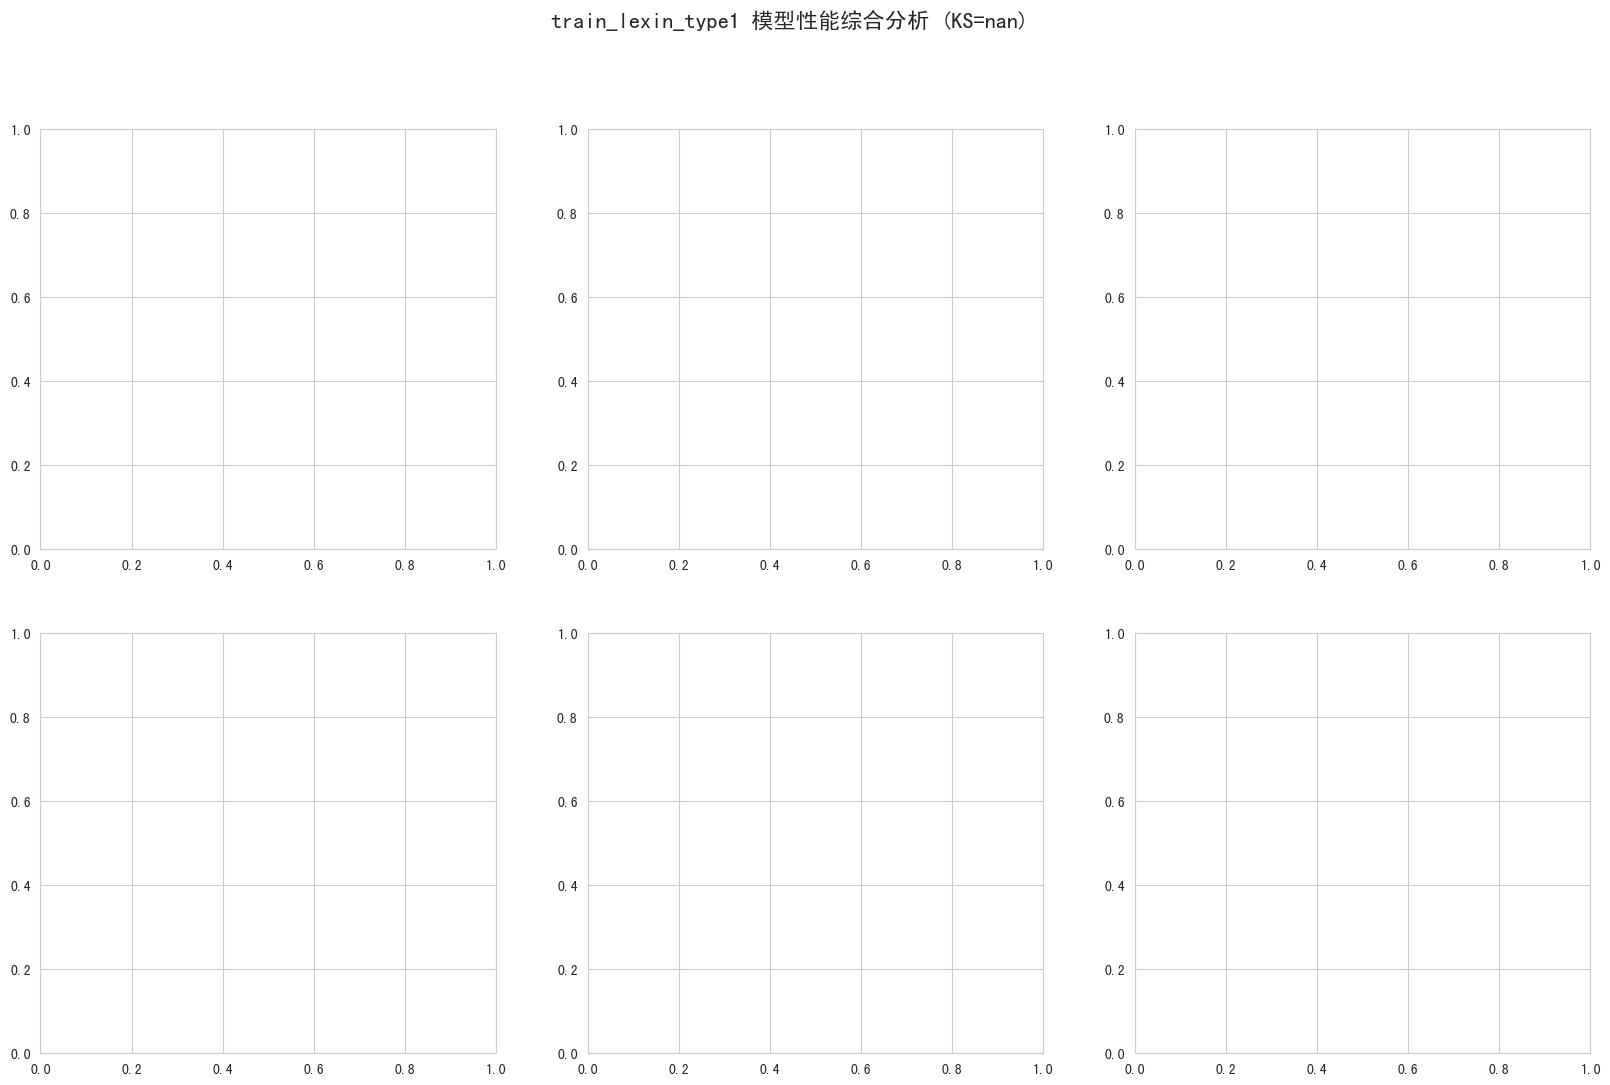

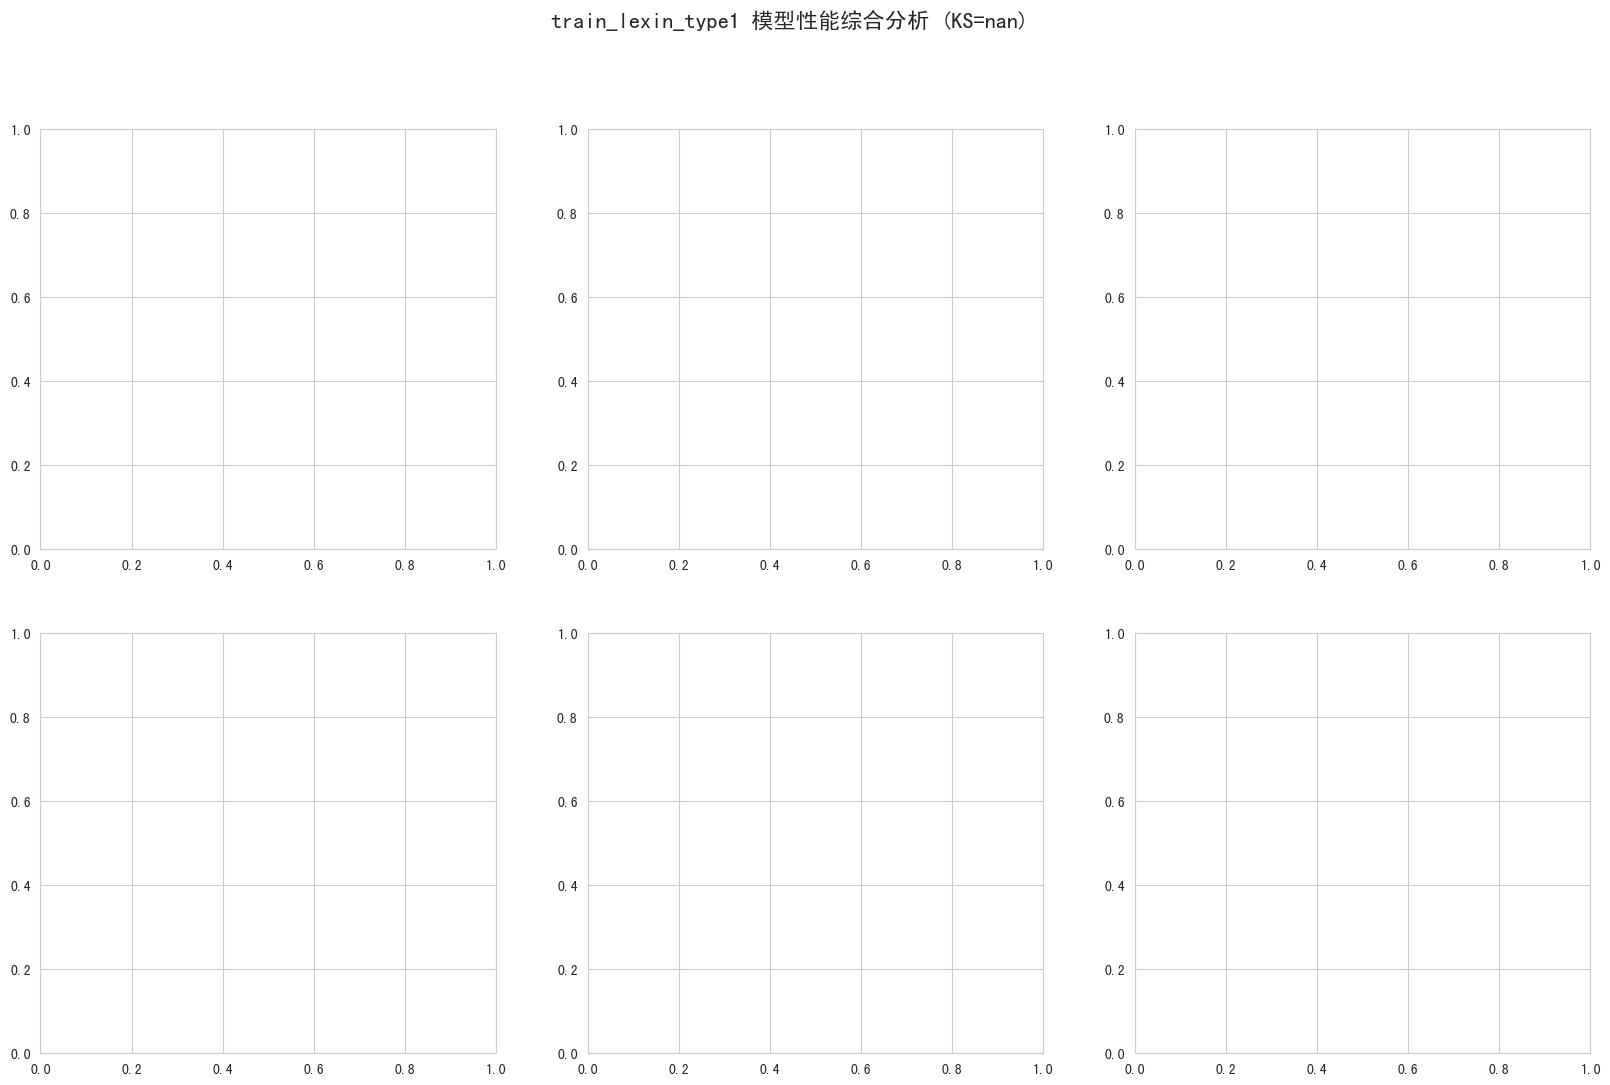

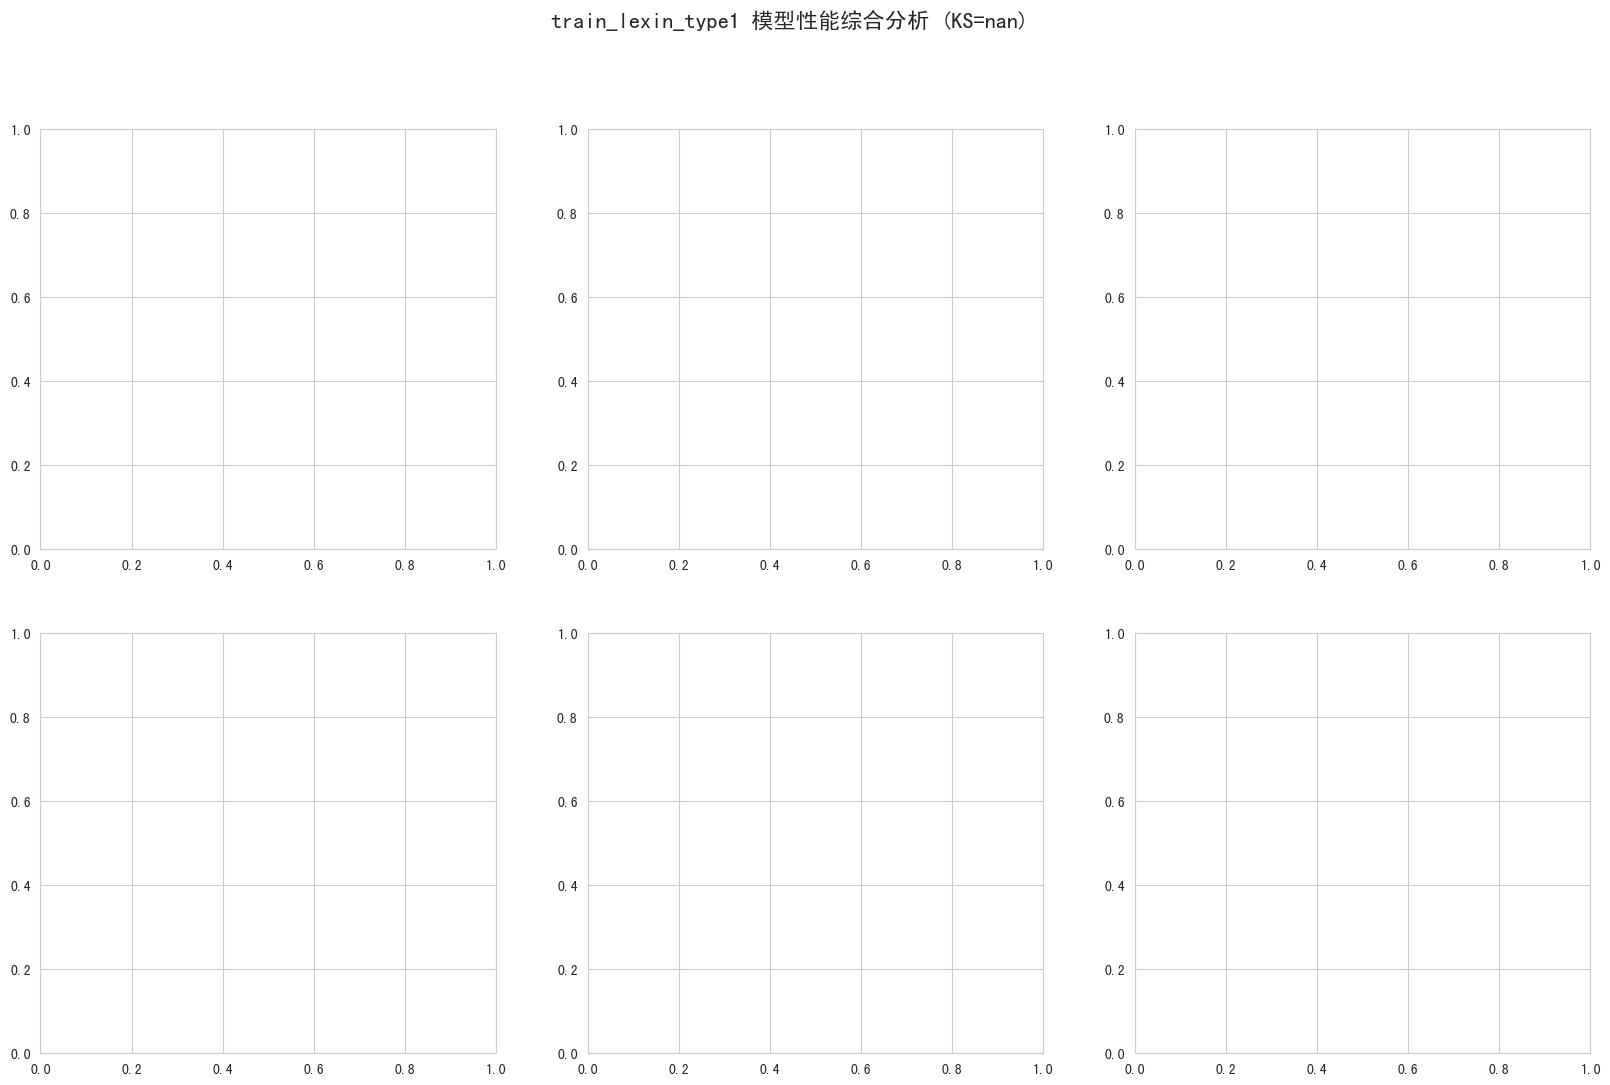

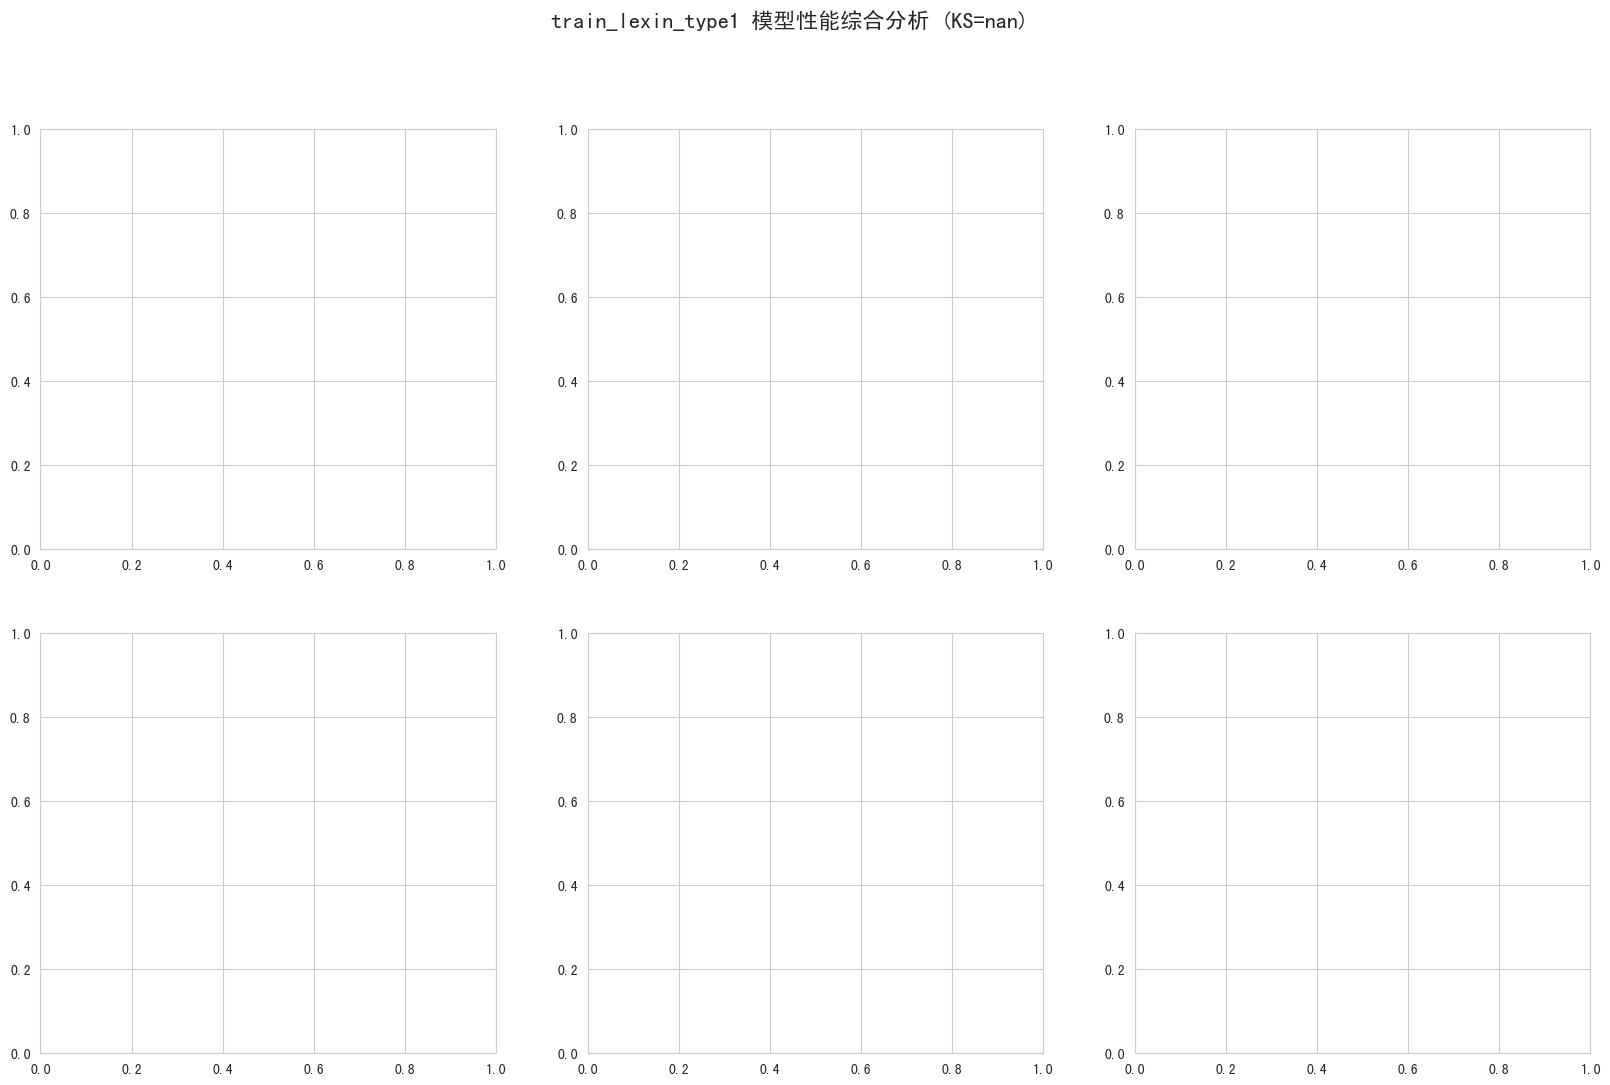

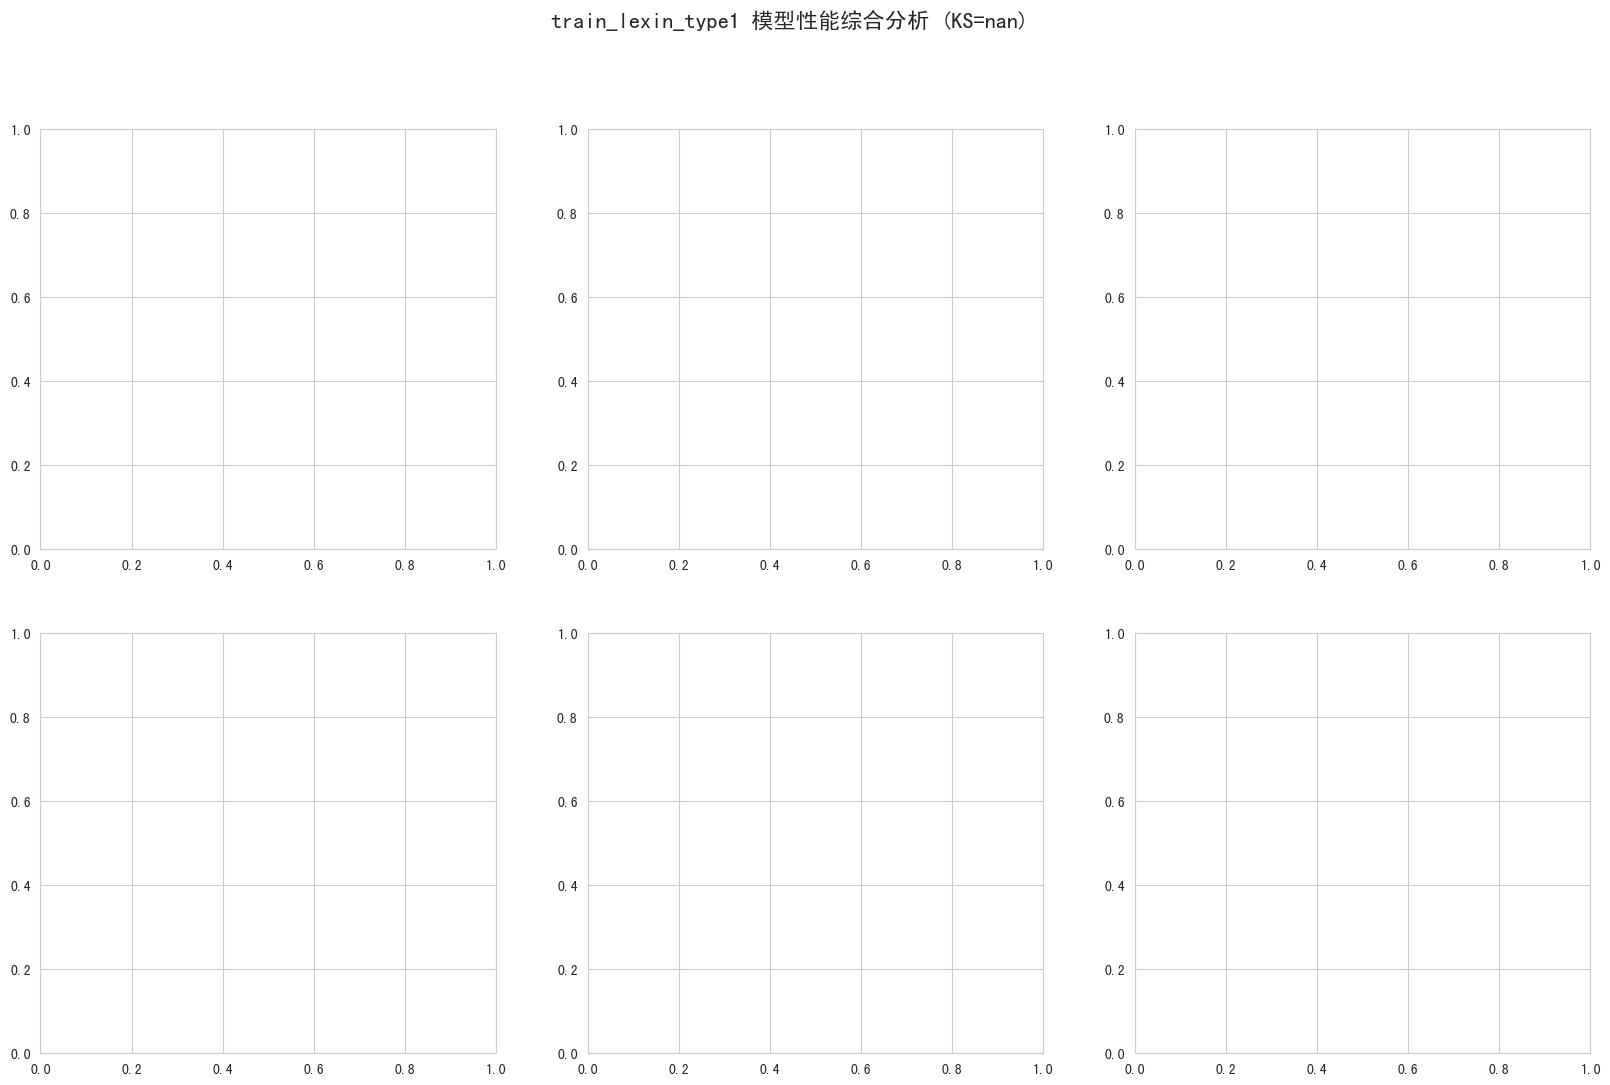

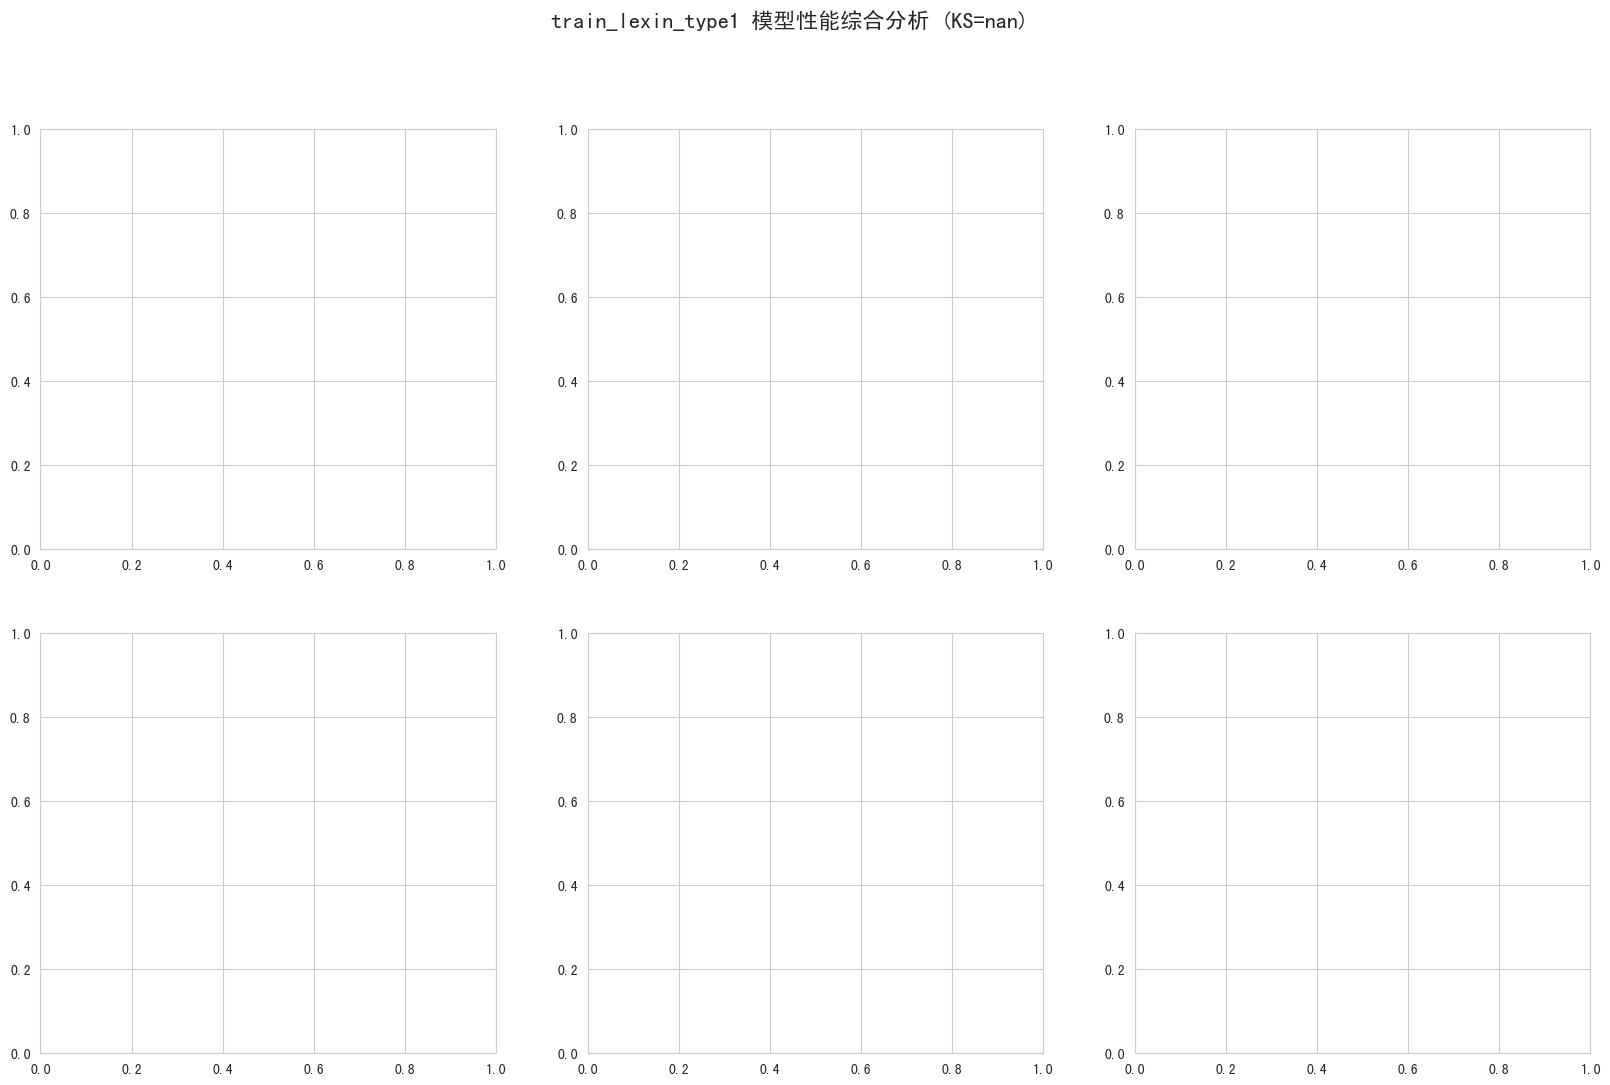

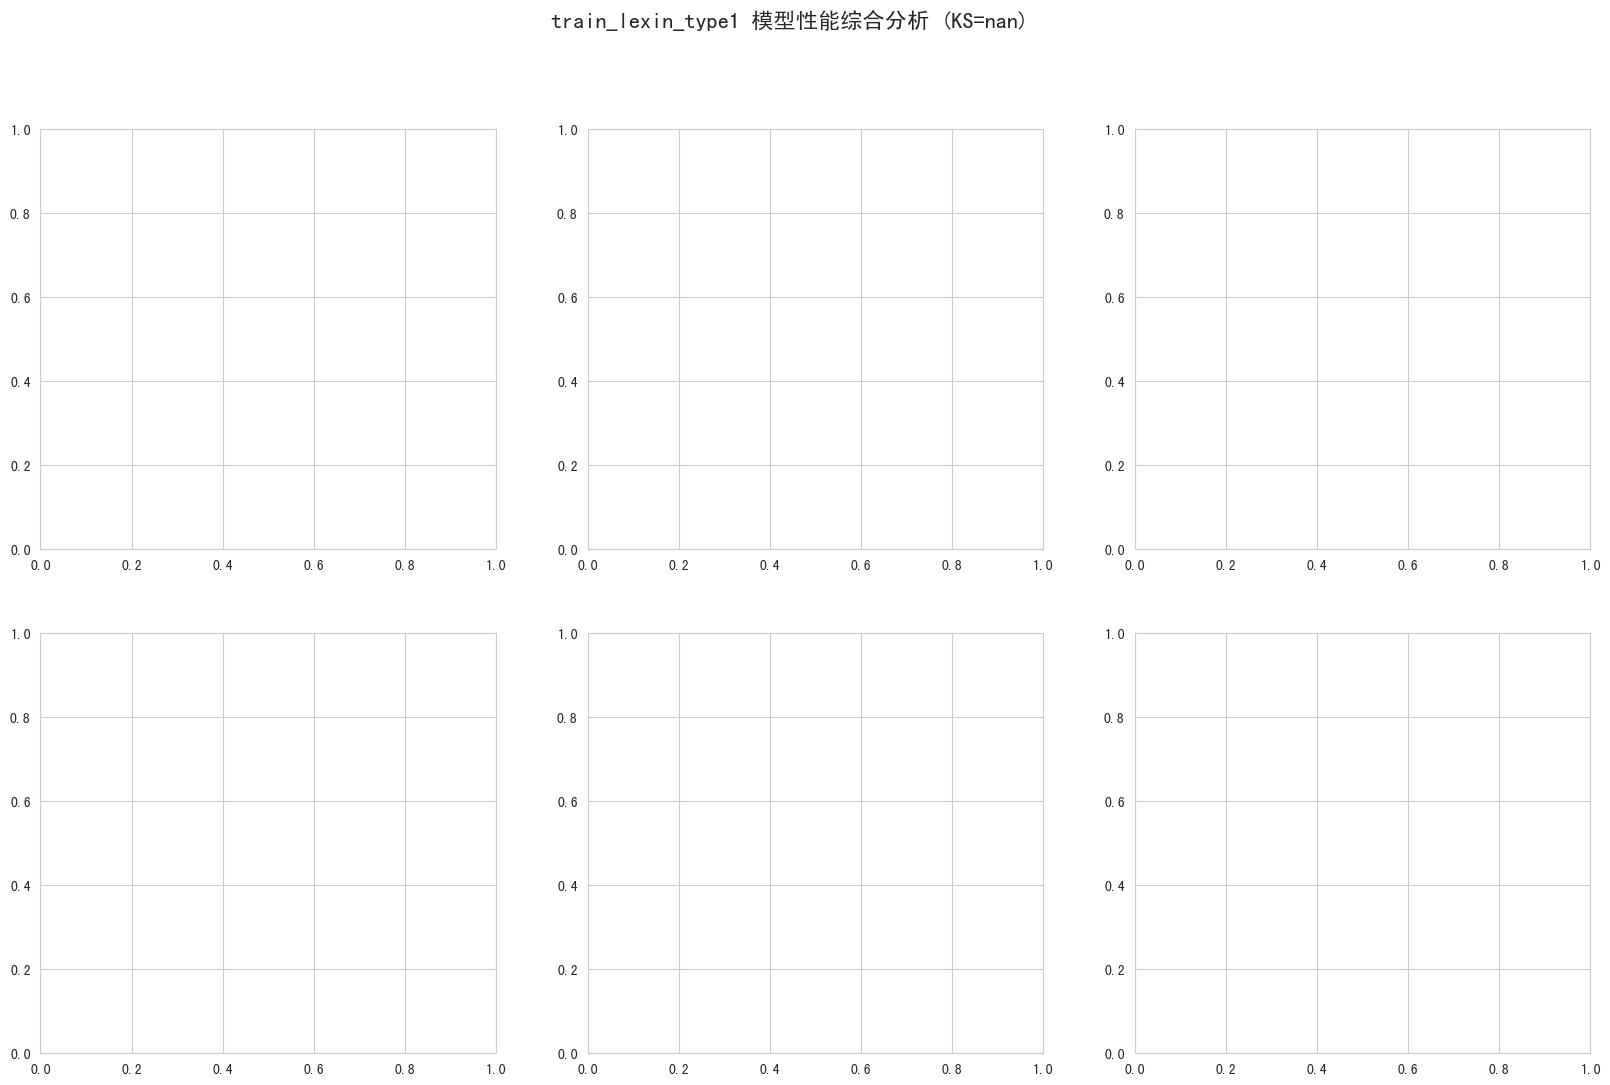

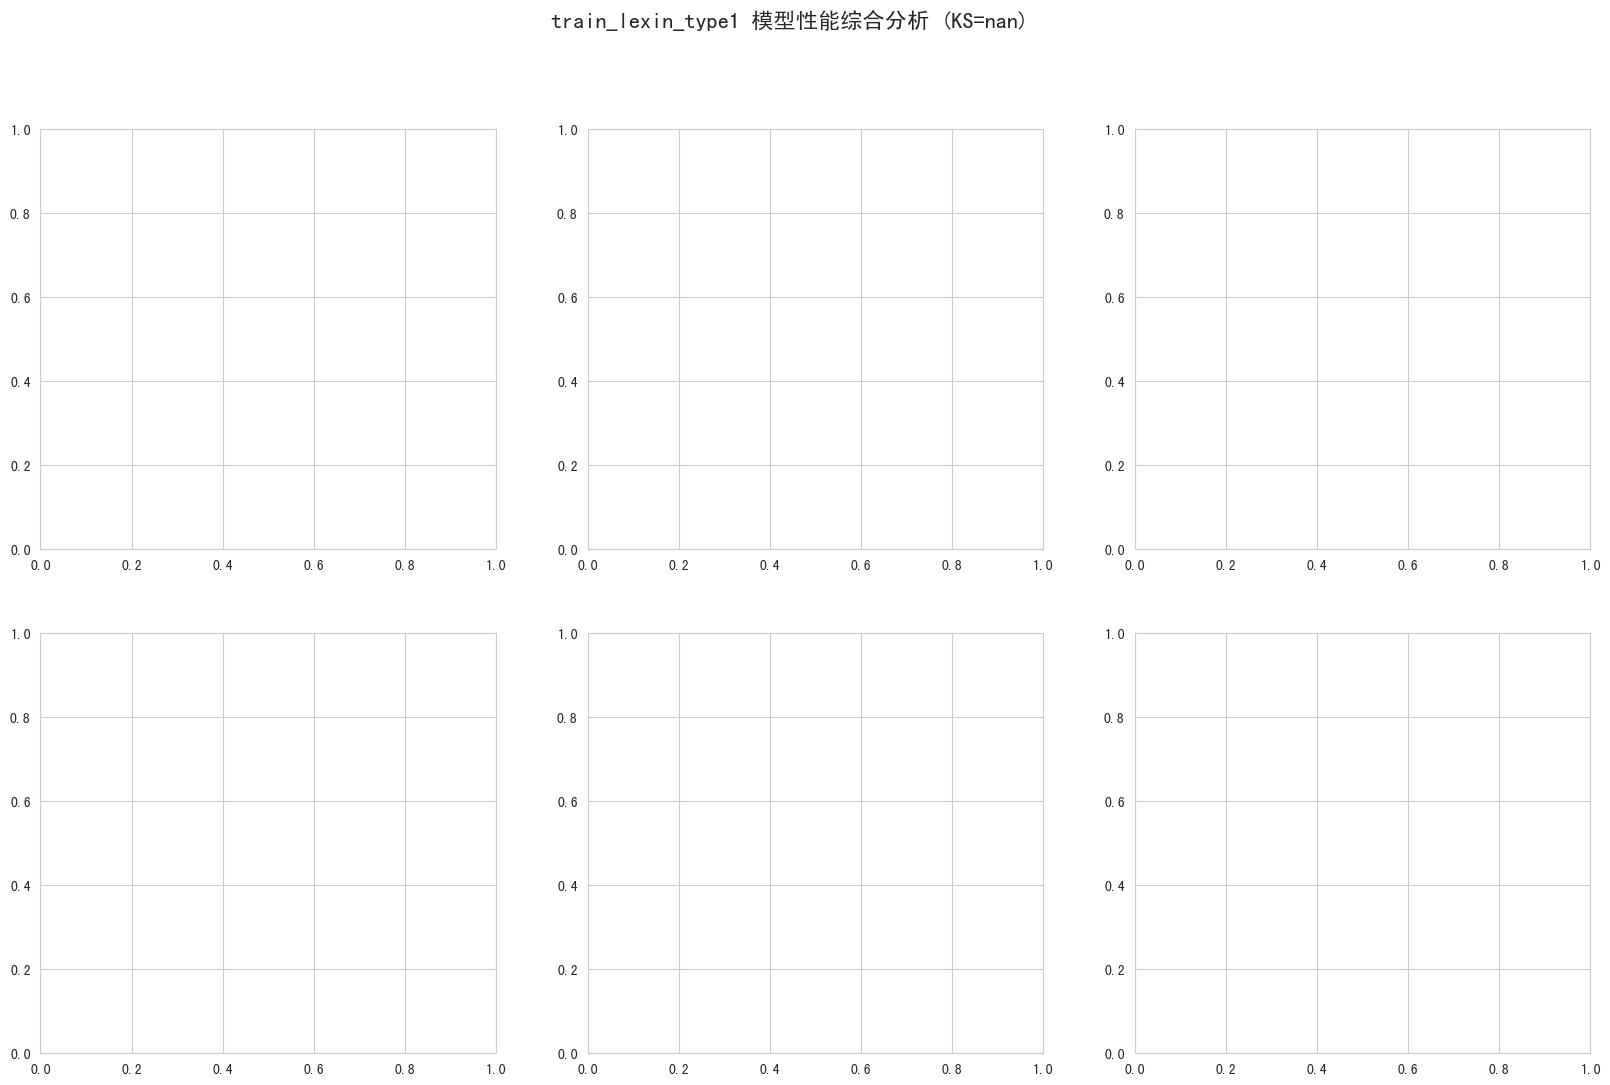

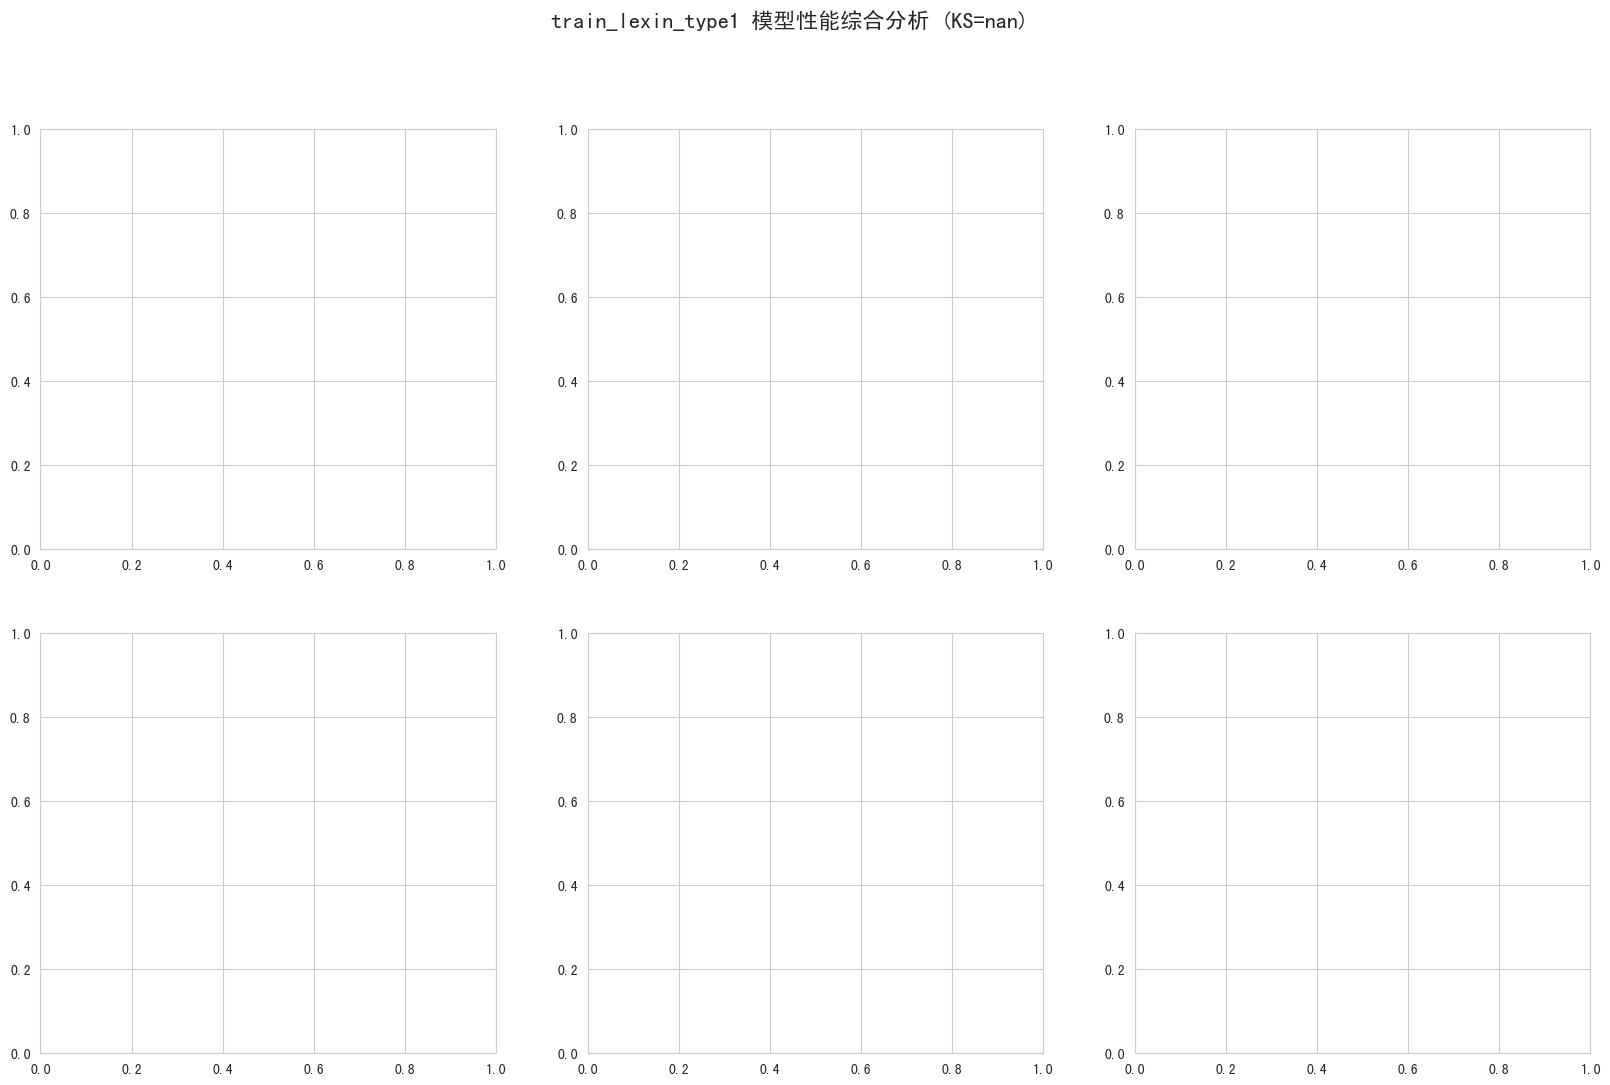

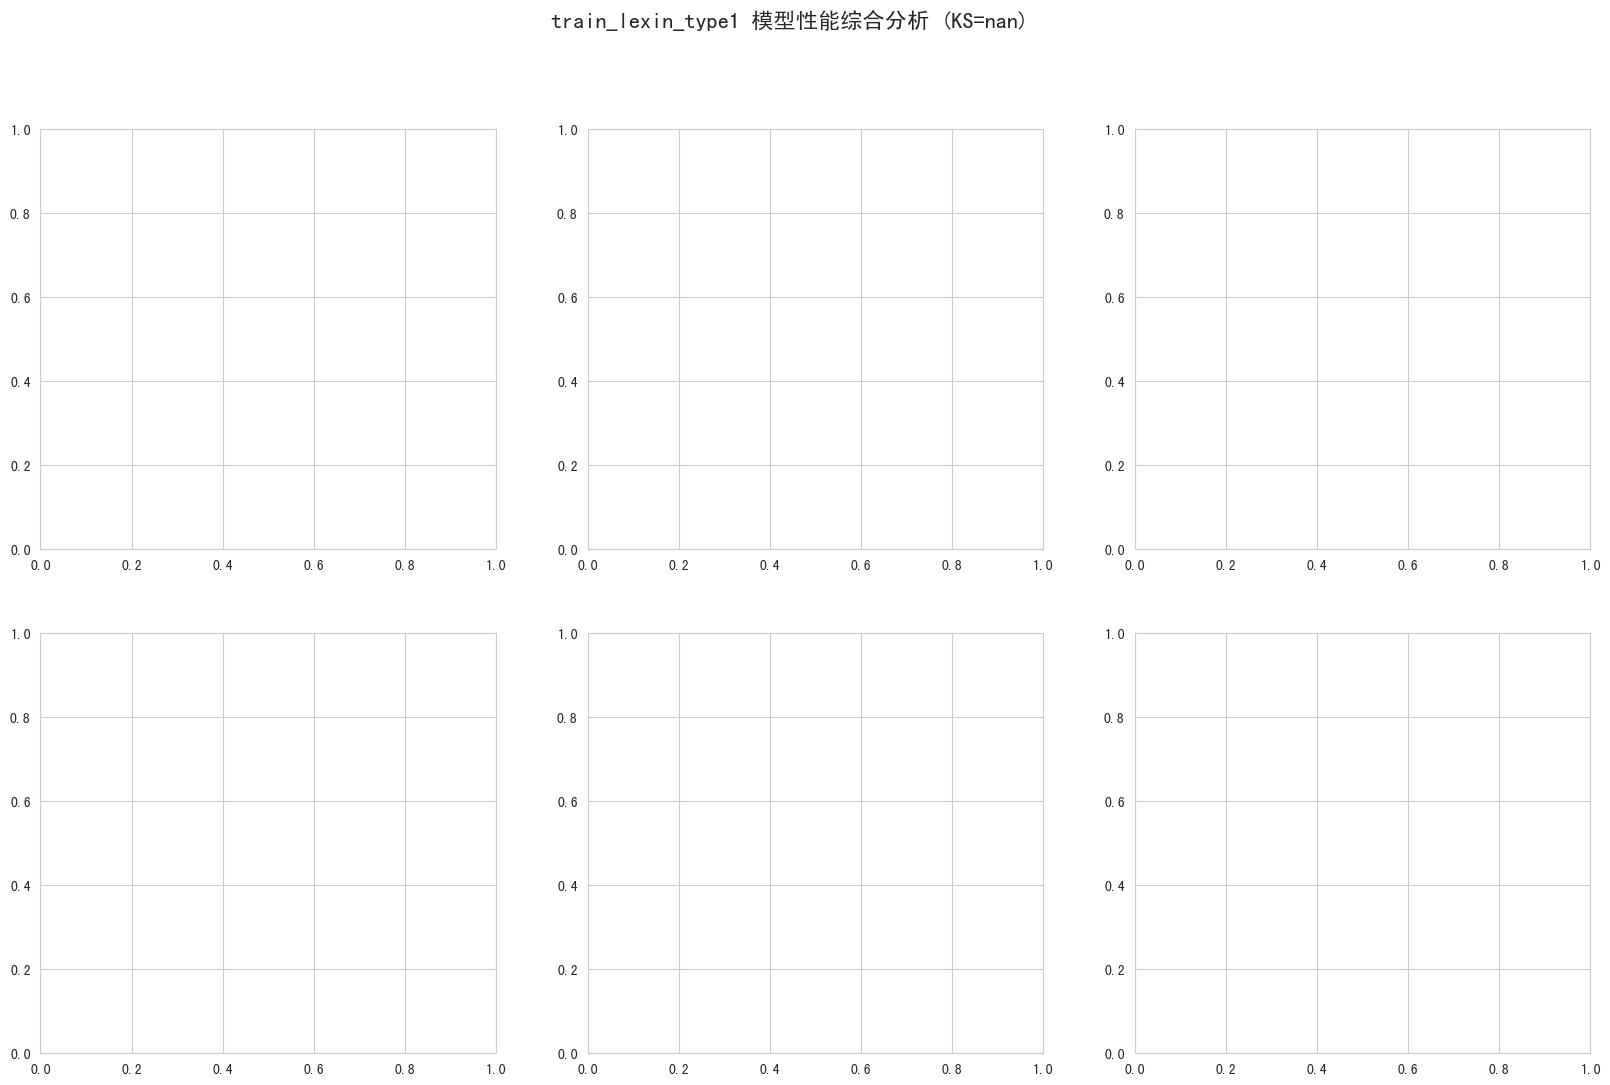

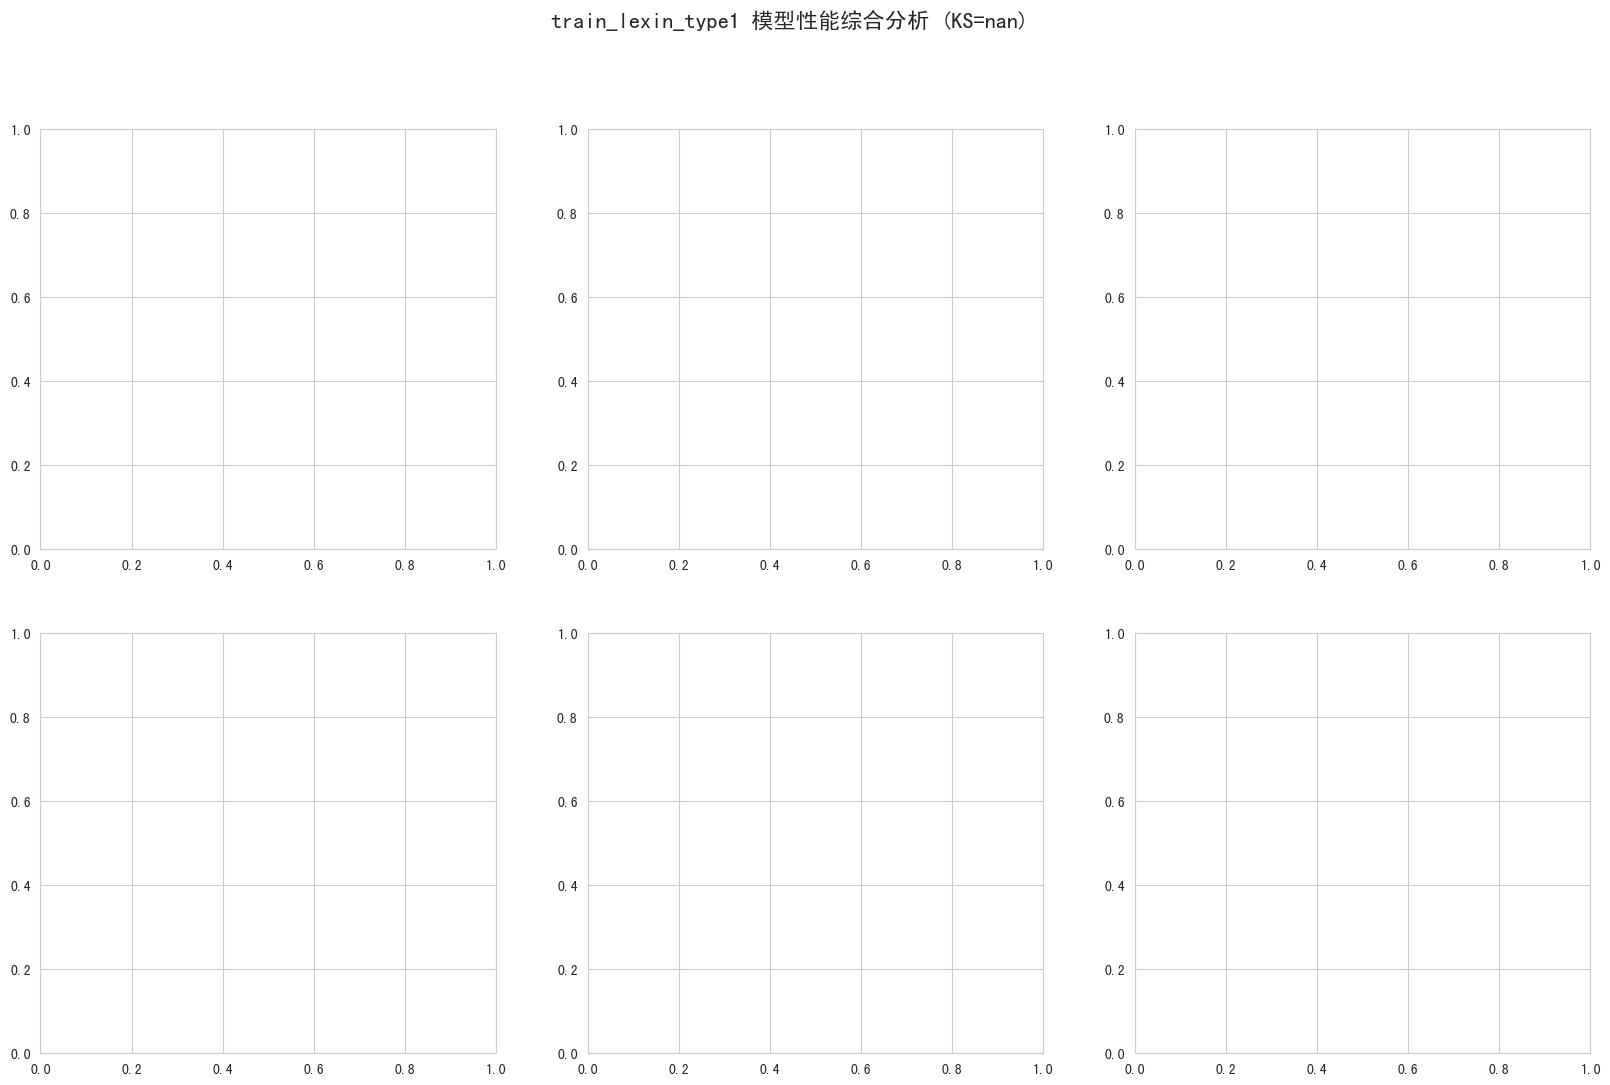

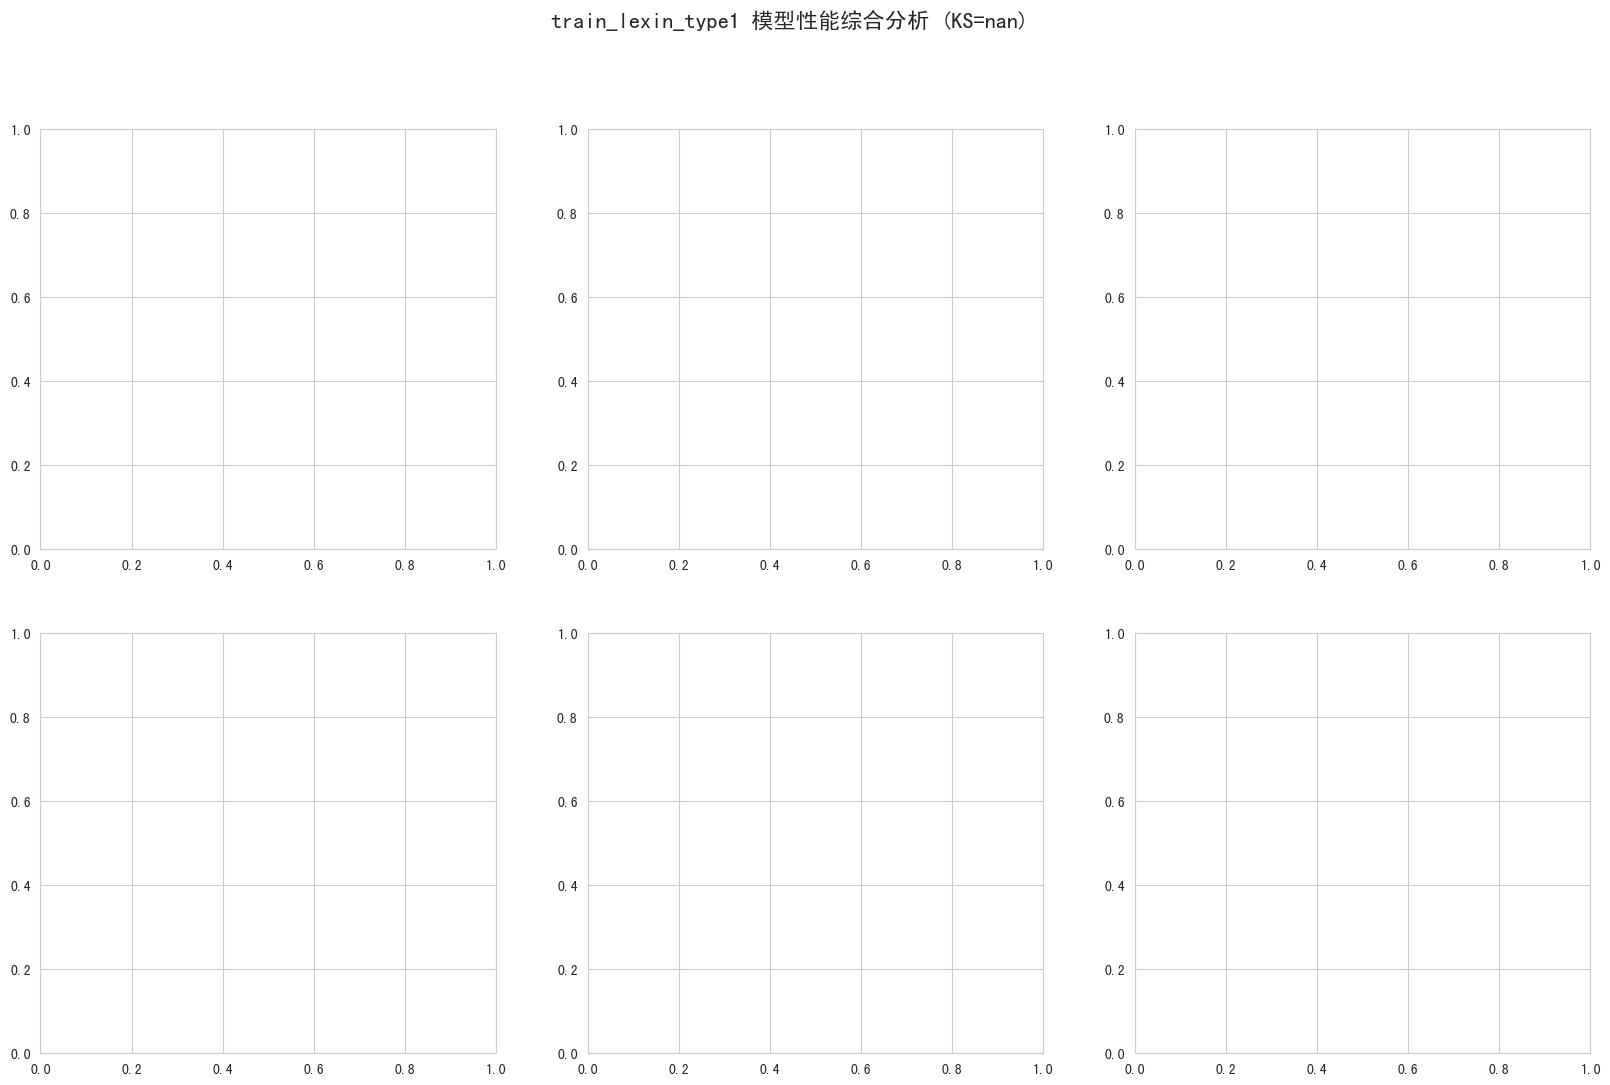

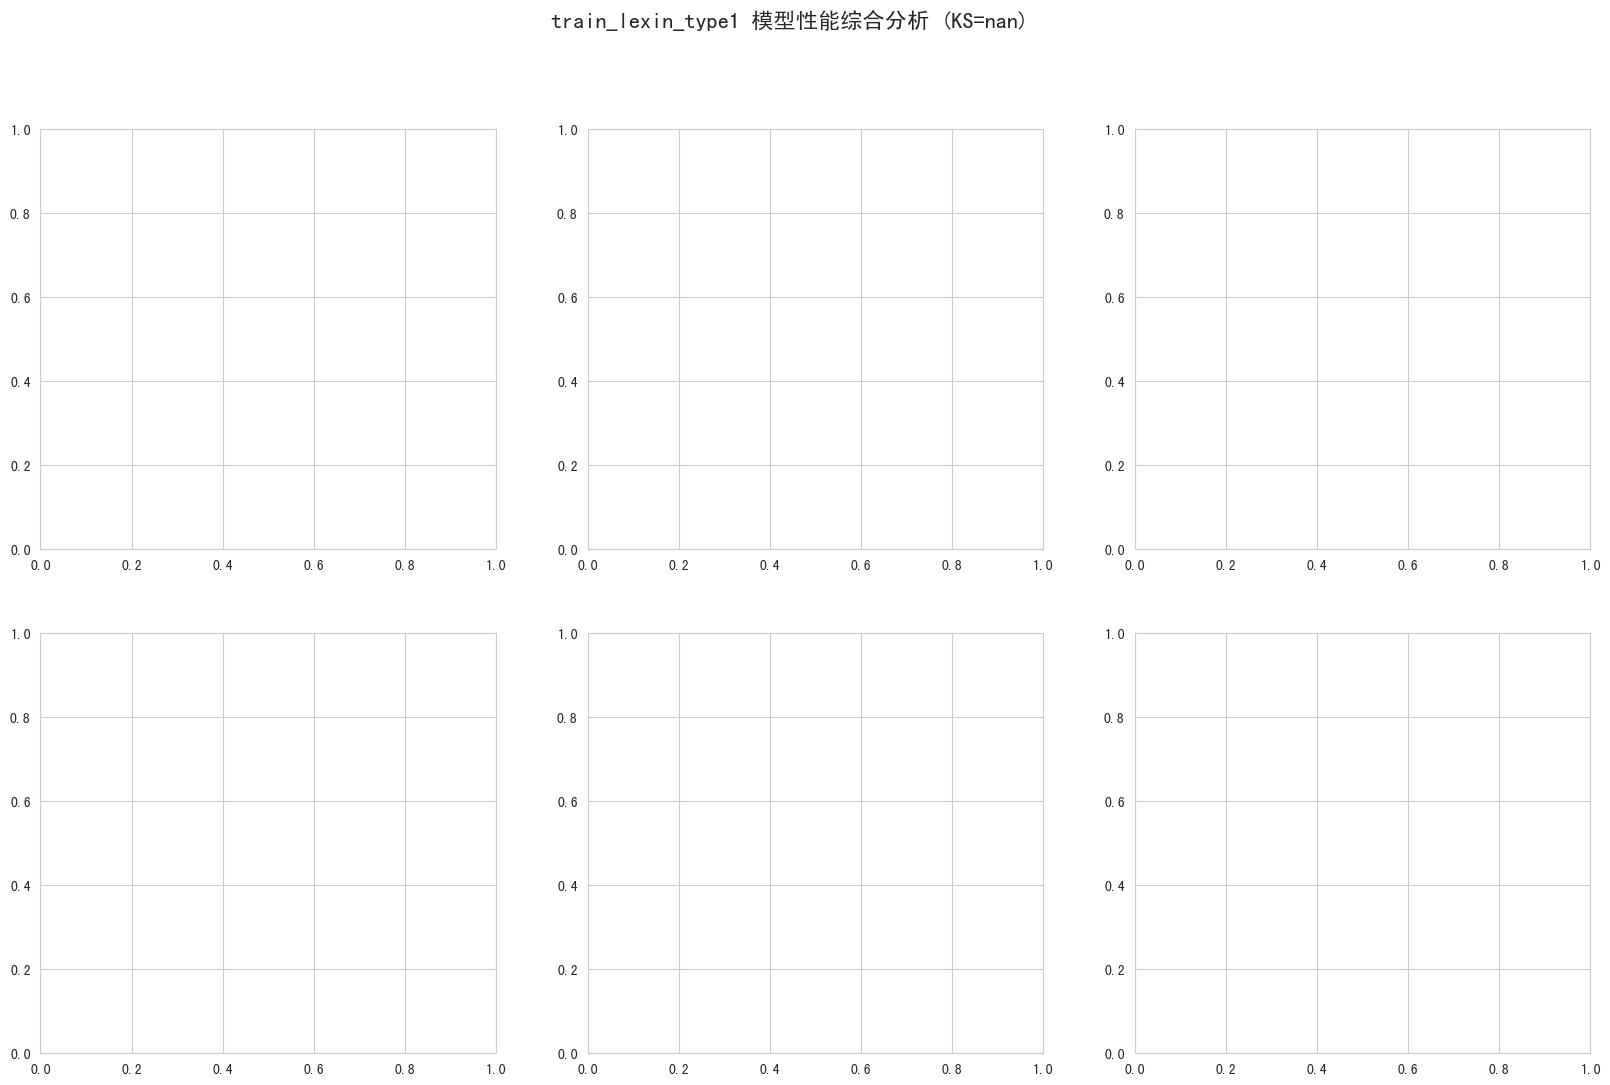

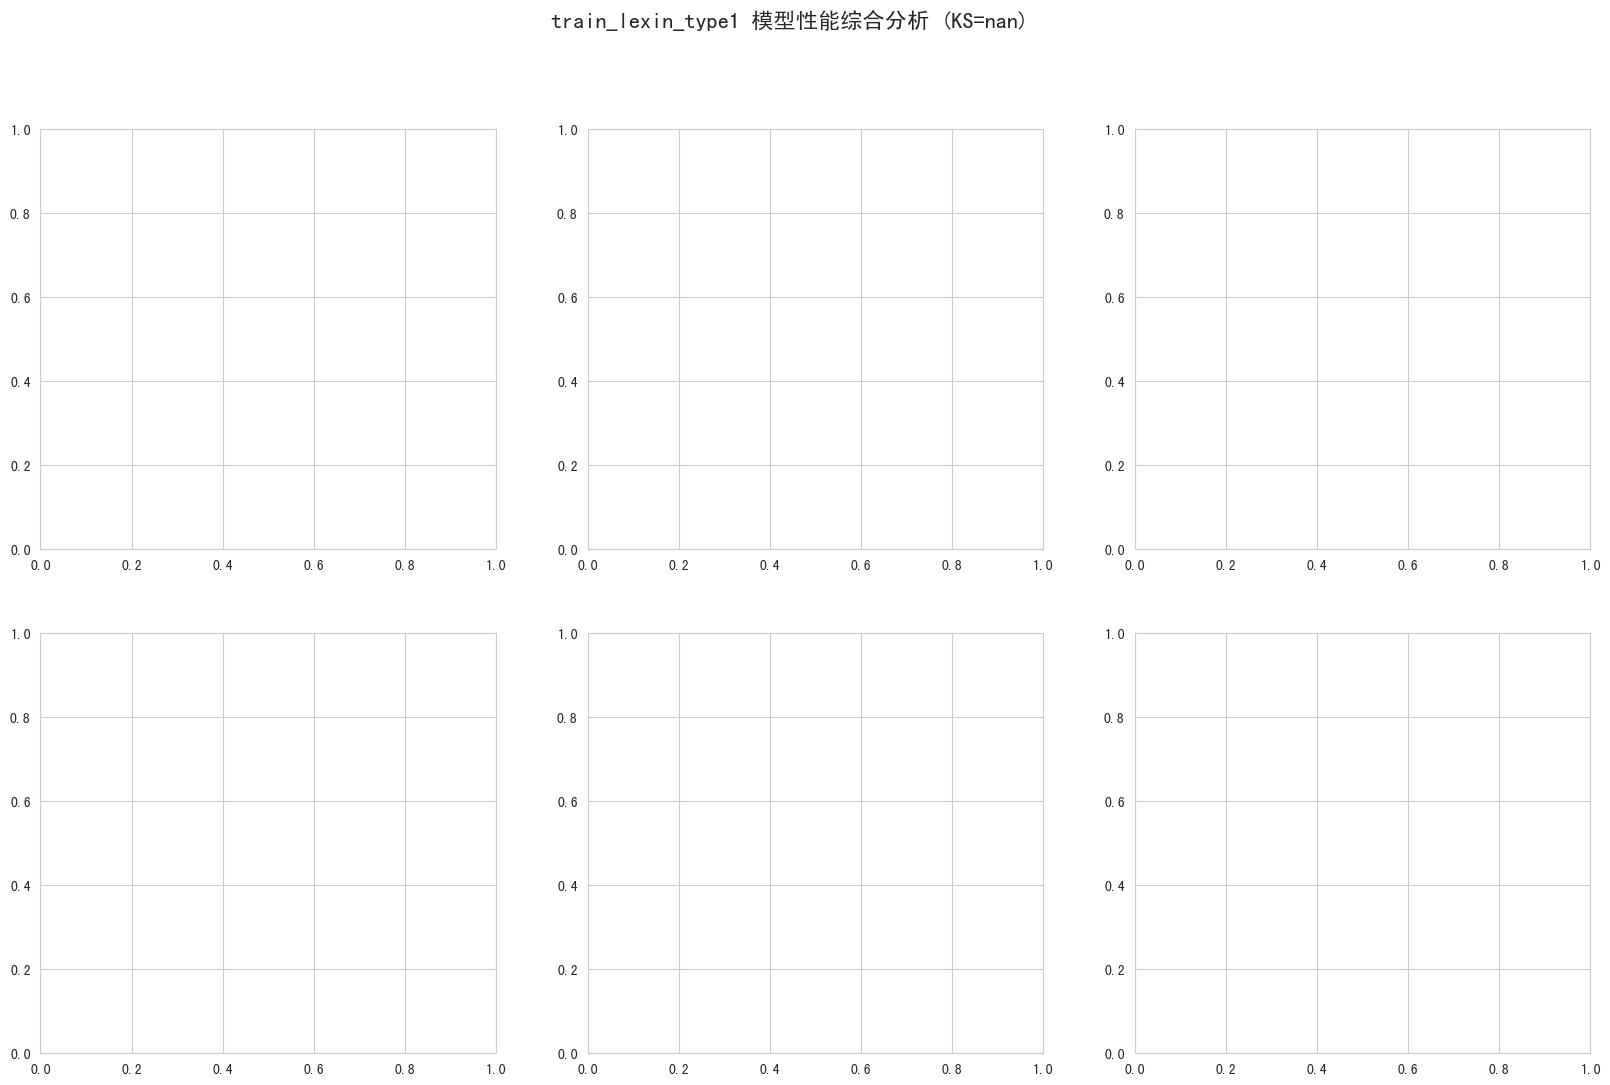

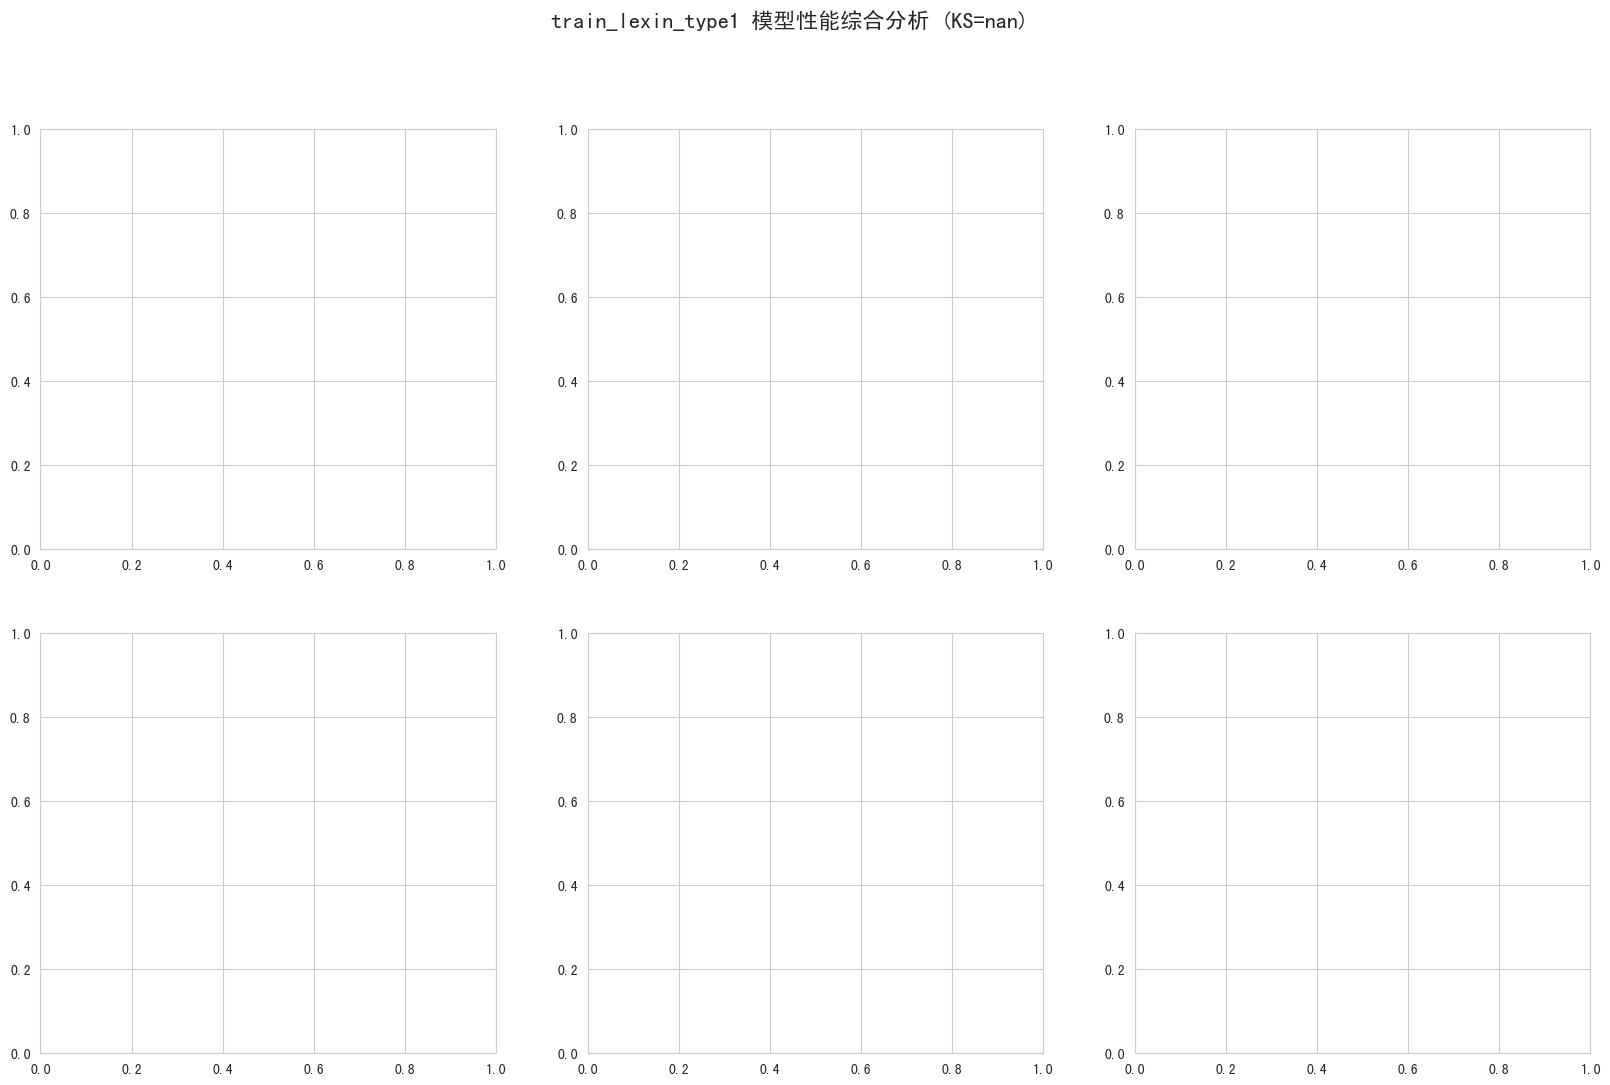

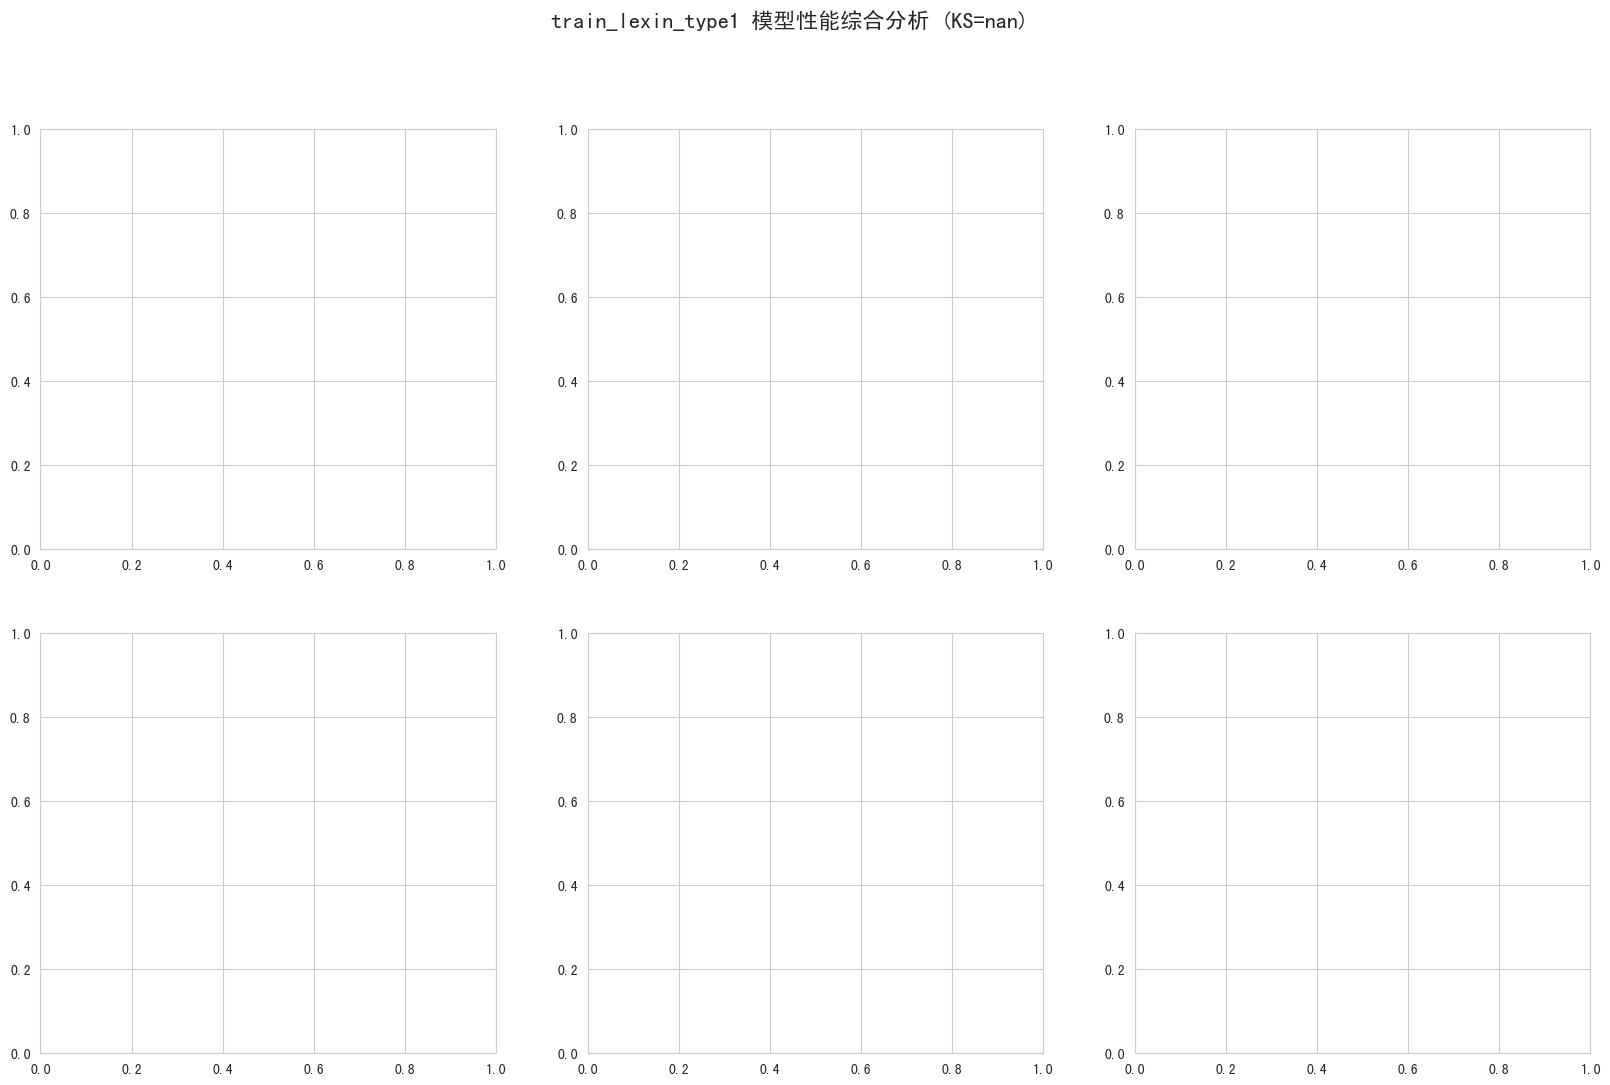

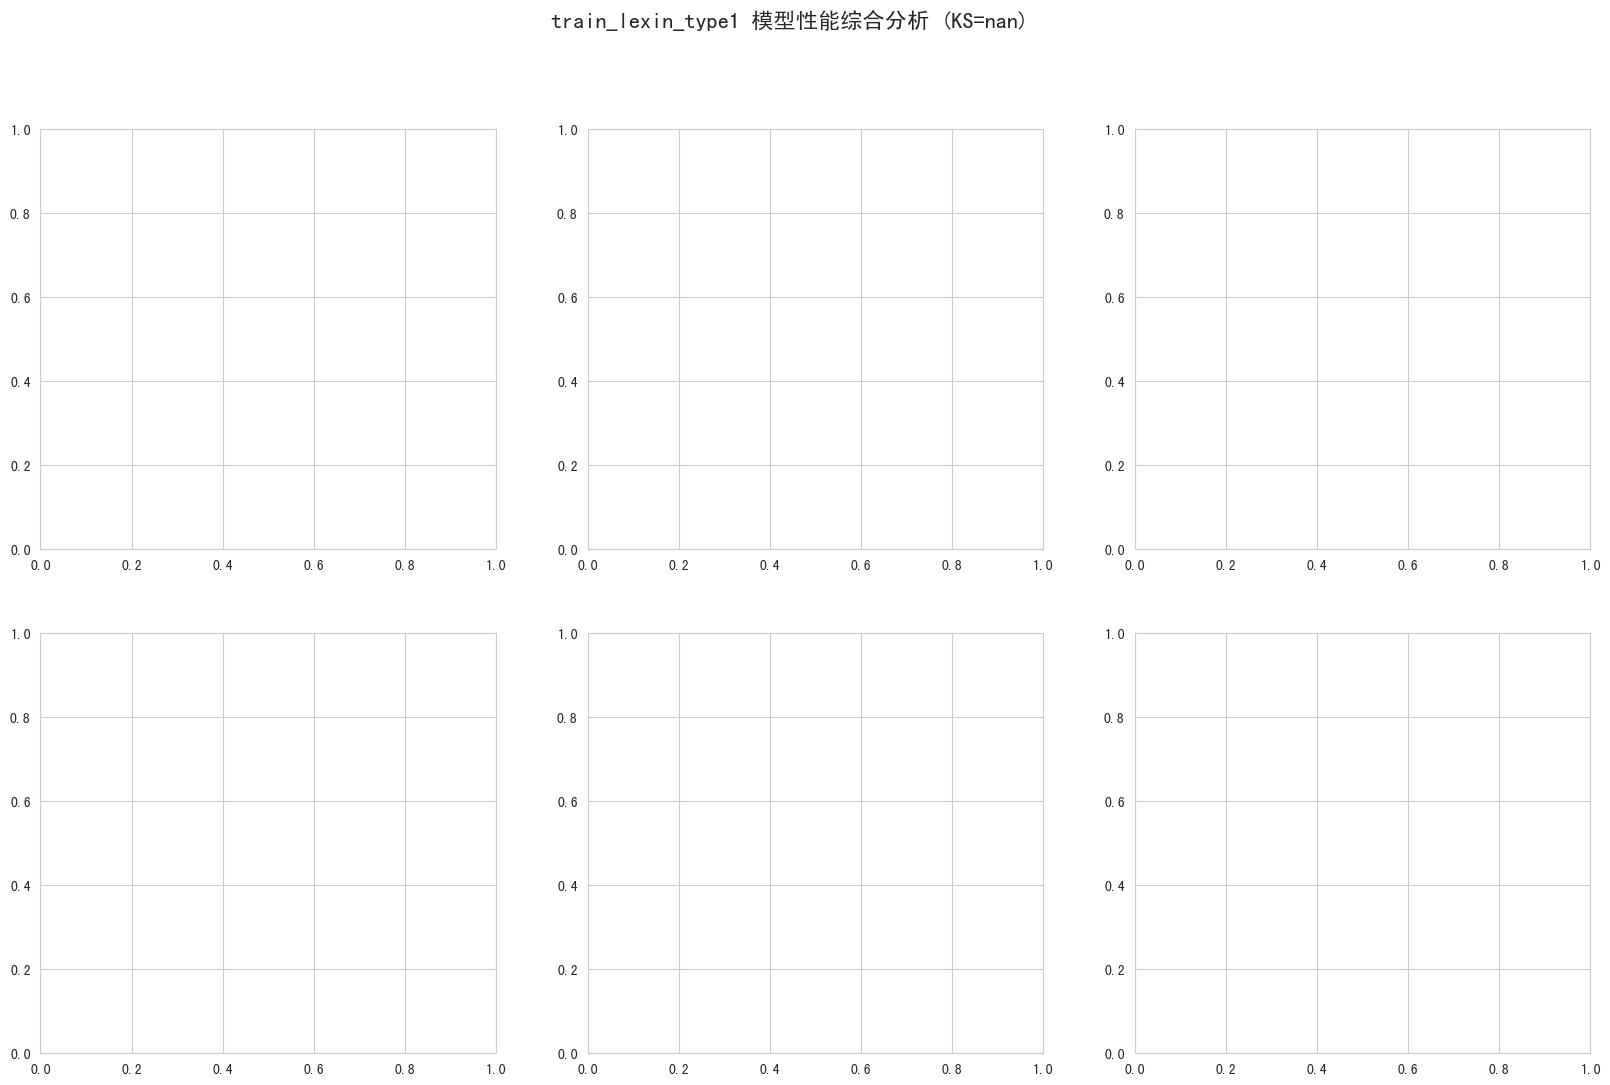

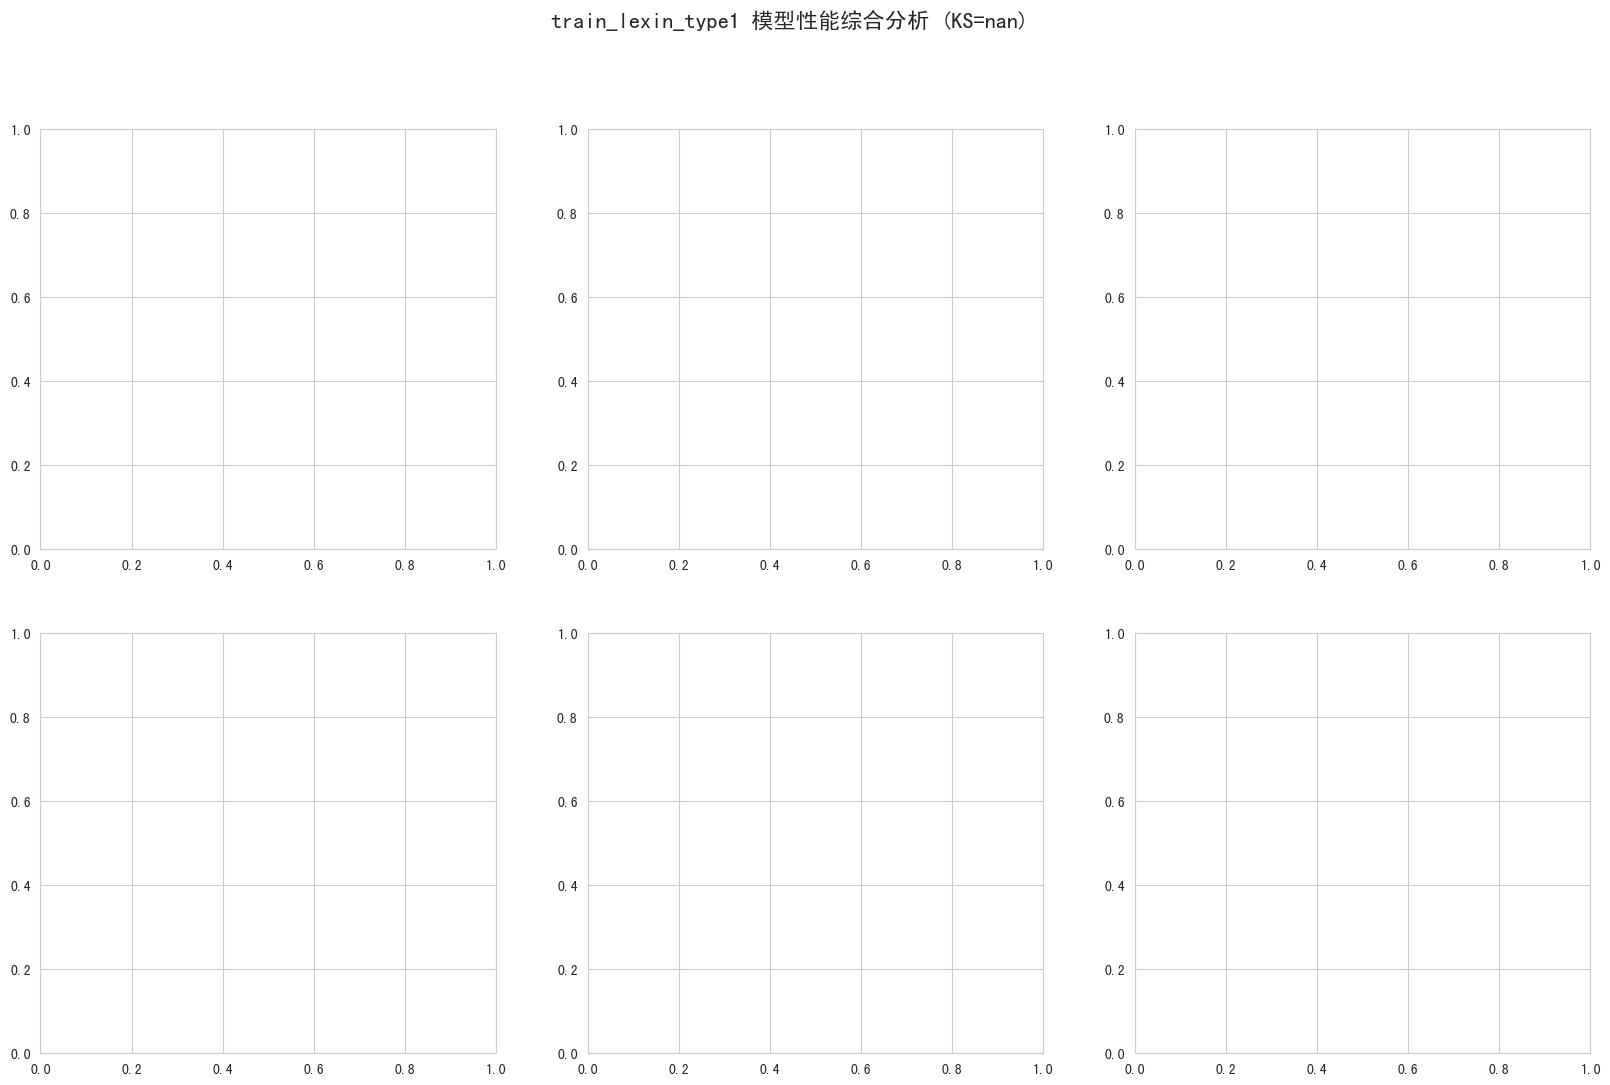

In [29]:
run_experiment_batch(LogisticRegression,
df_xc_ym[df_xc_ym['mid_sample_type'].isin(['1-train','2-ensemble'])],
df_xc_ym[df_xc_ym['mid_sample_type']=='3-oos'],
feas,
'flag',
candidate_parmas,
report_dir = 'report/',
ledger_path='report/ledger.csv',
score_col='ym_z62_prob',
sample_type_col = 'partner_name',
date_col = 'app_date'

)

In [57]:
df_xc_ym.columns[-30:]

Index(['category_order_money_180d_mobile',
       'category_order_money_180d_personalcare',
       'category_order_money_180d_mombaby',
       'category_order_money_180d_digital', 'category_order_money_180d_home',
       'category_order_money_180d_culture', 'phonenum', 'id_card', 'ym_prob',
       'xc_prob', 'b046_prob', 'b046_score', 'test_id', 'id_number', 'mobile',
       'apply_date', 'flag', 'enc_method', 'partner_name', 'pric_type_code',
       'pric_type_desc', '蜜蜂分_中利率版2_2_proba', '蜜蜂分_中利率版6_2_proba',
       'ym_prob_fill', 'ym_prob_valid', 'ym_prob_trans',
       '蜜蜂分_中利率版6_2_proba_fill', '蜜蜂分_中利率版6_2_proba_valid',
       '蜜蜂分_中利率版6_2_proba_trans', 'ym_z62_prob'],
      dtype='object')

In [59]:
df_xc_ym['pric_type_desc'].value_counts()

pric_type_desc
中利率    95627
高利率       55
Name: count, dtype: int64

In [30]:
params_lr = candidate_parmas[-1]

lr_model = LogisticRegression(**params_lr)
lr_model.fit(df_xc_ym[df_xc_ym['mid_sample_type'].isin(['1-train','2-ensemble'])][feas], df_xc_ym[df_xc_ym['mid_sample_type'].isin(['1-train','2-ensemble'])]['flag'])

LogisticRegression(C=1.4359912151349368, l1_ratio=0.5697485959697509,
                   max_iter=857, n_jobs=-1, penalty='elasticnet',
                   random_state=42, solver='saga')

In [31]:
import joblib
joblib.dump(lr_model, 'models/lr_model.pkl')

['models/lr_model.pkl']

In [32]:
df_xc_ym['ym_z62_prob'] = lr_model.predict_proba(df_xc_ym[feas])[:, 1]

In [34]:
from model_tools.evaluation.metrics import calculate_lift

In [36]:
# 对于df_xc_ym中的每一个'partner_name'，对比‘b046score'和'ym_z62_prob'的分箱Lift
for partner in df_xc_ym['partner_name'].unique():
    print(partner)
    df_partner = df_xc_ym[df_xc_ym['partner_name']==partner]
    display(calculate_lift(df_partner['flag'], df_partner['b046_score'], 10)[0])
    display(calculate_lift(df_partner['flag'], df_partner['ym_z62_prob'], 10)[0])
    print('---')

weipingfubang_highirr


,分箱,样本数,正样本数,负样本数,正样本率,Lift,概率范围,累积样本数,累积正样本数,累积正样本率,累积Lift,累积召回率
0,1,2110,472.0,1638.0,0.223697,0.826360,692.000-900.000,2110,472.0,0.223697,0.826360,0.082503
1,2,2110,568.0,1542.0,0.269194,0.994433,617.000-691.000,4220,1040.0,0.246445,0.910397,0.181786
2,3,2113,537.0,1576.0,0.254141,0.938825,563.000-616.000,6333,1577.0,0.249013,0.919882,0.275651
3,4,2087,479.0,1608.0,0.229516,0.847857,530.000-562.000,8420,2056.0,0.244181,0.902030,0.359378
4,5,2032,510.0,1522.0,0.250984,0.927163,507.000-529.000,10452,2566.0,0.245503,0.906916,0.448523
5,6,2191,544.0,1647.0,0.248288,0.917205,486.000-506.000,12643,3110.0,0.245986,0.908699,0.543611
6,7,2041,528.0,1513.0,0.258697,0.955654,467.000-485.000,14684,3638.0,0.247753,0.915225,0.635903
7,8,2175,594.0,1581.0,0.273103,1.008874,445.000-466.000,16859,4232.0,0.251023,0.927307,0.739731
8,9,2150,684.0,1466.0,0.318140,1.175242,419.000-444.000,19009,4916.0,0.258614,0.955350,0.859290
9,10,2125,805.0,1320.0,0.378824,1.399416,0.000-418.000,21134,5721.0,0.270701,1.000000,1.000000


,分箱,样本数,正样本数,负样本数,正样本率,Lift,概率范围,累积样本数,累积正样本数,累积正样本率,累积Lift,累积召回率
0,1,2114,997.0,1117.0,0.471618,1.742208,0.560-0.812,2114,997.0,0.471618,1.742208,0.174270
1,2,2113,758.0,1355.0,0.358732,1.325194,0.511-0.560,4227,1755.0,0.415188,1.533750,0.306765
2,3,2113,693.0,1420.0,0.327970,1.211556,0.476-0.511,6340,2448.0,0.386120,1.426369,0.427897
3,4,2114,627.0,1487.0,0.296594,1.095651,0.445-0.476,8454,3075.0,0.363733,1.343670,0.537493
4,5,2113,565.0,1548.0,0.267392,0.987777,0.416-0.445,10567,3640.0,0.344469,1.272505,0.636252
5,6,2113,521.0,1592.0,0.246569,0.910852,0.388-0.416,12680,4161.0,0.328155,1.212239,0.727320
6,7,2114,480.0,1634.0,0.227058,0.838776,0.357-0.388,14794,4641.0,0.313708,1.158873,0.811222
7,8,2113,397.0,1716.0,0.187885,0.694066,0.323-0.357,16907,5038.0,0.297983,1.100782,0.880615
8,9,2113,379.0,1734.0,0.179366,0.662597,0.276-0.323,19020,5417.0,0.284805,1.052103,0.946862
9,10,2114,304.0,1810.0,0.143803,0.531225,0.070-0.276,21134,5721.0,0.270701,1.000000,1.000000


---
weipingfubang_lowerirr


,分箱,样本数,正样本数,负样本数,正样本率,Lift,概率范围,累积样本数,累积正样本数,累积正样本率,累积Lift,累积召回率
0,1,585,102.0,483.0,0.174359,0.744557,744.000-900.000,585,102.0,0.174359,0.744557,0.073118
1,2,601,140.0,461.0,0.232945,0.994734,687.000-743.000,1186,242.0,0.204047,0.871333,0.173477
2,3,601,130.0,471.0,0.216306,0.923682,621.000-686.000,1787,372.0,0.208170,0.888939,0.266667
3,4,587,130.0,457.0,0.221465,0.945711,573.000-620.000,2374,502.0,0.211457,0.902976,0.359857
4,5,587,125.0,462.0,0.212947,0.909338,544.000-572.000,2961,627.0,0.211753,0.904238,0.449462
5,6,598,128.0,470.0,0.214047,0.914034,520.000-543.000,3559,755.0,0.212138,0.905884,0.541219
6,7,588,130.0,458.0,0.221088,0.944103,499.000-519.000,4147,885.0,0.213407,0.911303,0.634409
7,8,618,151.0,467.0,0.244337,1.043378,474.000-498.000,4765,1036.0,0.217419,0.928432,0.742652
8,9,586,156.0,430.0,0.266212,1.136790,444.000-473.000,5351,1192.0,0.222762,0.951250,0.854480
9,10,606,203.0,403.0,0.334983,1.430464,0.000-443.000,5957,1395.0,0.234178,1.000000,1.000000


,分箱,样本数,正样本数,负样本数,正样本率,Lift,概率范围,累积样本数,累积正样本数,累积正样本率,累积Lift,累积召回率
0,1,596,252.0,344.0,0.422819,1.805542,0.541-0.761,596,252.0,0.422819,1.805542,0.180645
1,2,596,194.0,402.0,0.325503,1.389981,0.488-0.541,1192,446.0,0.374161,1.597762,0.319713
2,3,595,173.0,422.0,0.290756,1.241602,0.449-0.488,1787,619.0,0.346391,1.479175,0.443728
3,4,596,139.0,457.0,0.233221,0.995914,0.418-0.449,2383,758.0,0.318086,1.358309,0.543369
4,5,595,132.0,463.0,0.221849,0.947350,0.387-0.418,2978,890.0,0.298858,1.276200,0.637993
5,6,596,117.0,479.0,0.196309,0.838288,0.355-0.387,3574,1007.0,0.281757,1.203174,0.721864
6,7,596,109.0,487.0,0.182886,0.780969,0.326-0.355,4170,1116.0,0.267626,1.142830,0.800000
7,8,595,105.0,490.0,0.176471,0.753574,0.292-0.326,4765,1221.0,0.256243,1.094224,0.875269
8,9,596,104.0,492.0,0.174497,0.745144,0.249-0.292,5361,1325.0,0.247155,1.055415,0.949821
9,10,596,70.0,526.0,0.117450,0.501540,0.097-0.249,5957,1395.0,0.234178,1.000000,1.000000


... (78 outputs left out)

---
海尔(蚂蚁API贷中)


,分箱,样本数,正样本数,负样本数,正样本率,Lift,概率范围,累积样本数,累积正样本数,累积正样本率,累积Lift,累积召回率
0,1,2,0.0,2.0,0.0,0.00,660.000-662.000,2,0.0,0.000000,0.000000,0.0
1,2,1,0.0,1.0,0.0,0.00,641.000-641.000,3,0.0,0.000000,0.000000,0.0
2,3,1,0.0,1.0,0.0,0.00,603.000-603.000,4,0.0,0.000000,0.000000,0.0
3,4,1,0.0,1.0,0.0,0.00,494.000-494.000,5,0.0,0.000000,0.000000,0.0
4,5,1,0.0,1.0,0.0,0.00,486.000-486.000,6,0.0,0.000000,0.000000,0.0
5,6,2,1.0,1.0,0.5,3.25,453.000-483.000,8,1.0,0.125000,0.812500,0.5
6,7,1,0.0,1.0,0.0,0.00,452.000-452.000,9,1.0,0.111111,0.722222,0.5
7,8,1,0.0,1.0,0.0,0.00,444.000-444.000,10,1.0,0.100000,0.650000,0.5
8,9,1,1.0,0.0,1.0,6.50,411.000-411.000,11,2.0,0.181818,1.181818,1.0
9,10,2,0.0,2.0,0.0,0.00,382.000-402.000,13,2.0,0.153846,1.000000,1.0


,分箱,样本数,正样本数,负样本数,正样本率,Lift,概率范围,累积样本数,累积正样本数,累积正样本率,累积Lift,累积召回率
0,1,2,0.0,2.0,0.0,0.00,0.579-0.670,2,0.0,0.000000,0.000000,0.0
1,2,1,0.0,1.0,0.0,0.00,0.561-0.561,3,0.0,0.000000,0.000000,0.0
2,3,1,0.0,1.0,0.0,0.00,0.556-0.556,4,0.0,0.000000,0.000000,0.0
3,4,1,0.0,1.0,0.0,0.00,0.528-0.528,5,0.0,0.000000,0.000000,0.0
4,5,1,1.0,0.0,1.0,6.50,0.508-0.508,6,1.0,0.166667,1.083333,0.5
5,6,2,1.0,1.0,0.5,3.25,0.462-0.499,8,2.0,0.250000,1.625000,1.0
6,7,1,0.0,1.0,0.0,0.00,0.460-0.460,9,2.0,0.222222,1.444444,1.0
7,8,1,0.0,1.0,0.0,0.00,0.446-0.446,10,2.0,0.200000,1.300000,1.0
8,9,1,0.0,1.0,0.0,0.00,0.361-0.361,11,2.0,0.181818,1.181818,1.0
9,10,2,0.0,2.0,0.0,0.00,0.345-0.360,13,2.0,0.153846,1.000000,1.0


---


In [ ]:
df_xc_ym['diff'] = df_xc_ym['ym_z62_prob']-df_xc_ym['b046_score']
b046_score[df_xc_ym['b046_score']!=0][df_xc_ym['ym_z62_prob']!=0]['diff'].describe()


count    95597.000000
mean      -537.304375
std        109.226929
min       -899.929002
25%       -596.722980
50%       -512.637595
75%       -457.548540
max       -299.159159
Name: diff, dtype: float64

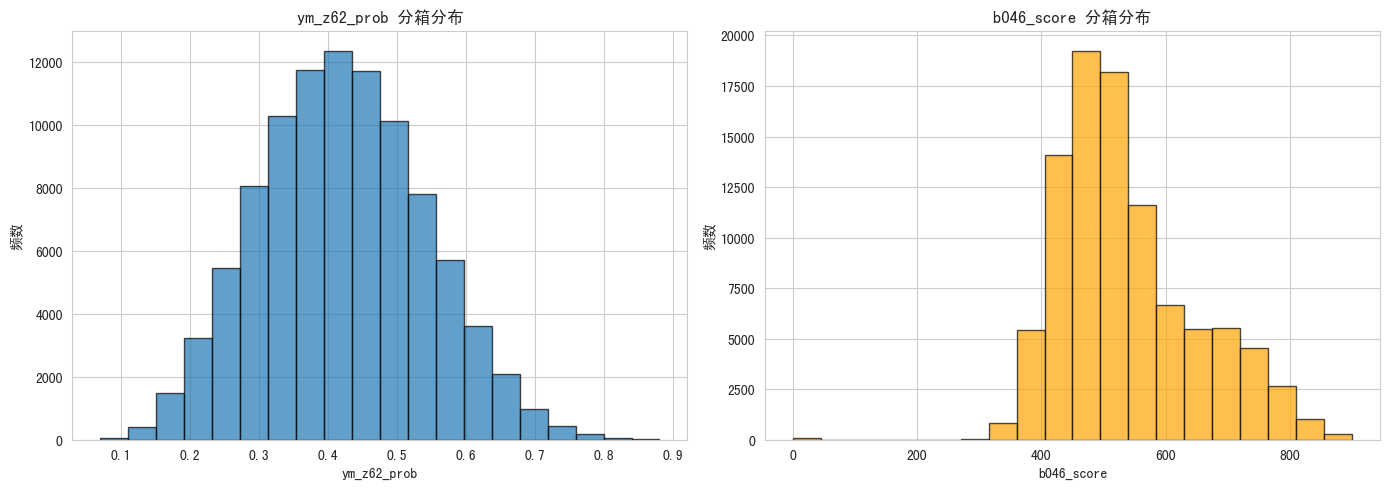

Pearson相关系数: -0.5179
Spearman相关系数: -0.5647


In [44]:
# 画出df_xc_ym中m_z62_prob和b046_score的分箱分布，计算他们的相关性

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# m_z62_prob 分箱分布
axes[0].hist(df_xc_ym['ym_z62_prob'].dropna(), bins=20, edgecolor='black', alpha=0.7)
axes[0].set_title('ym_z62_prob 分箱分布')
axes[0].set_xlabel('ym_z62_prob')
axes[0].set_ylabel('频数')

# b046_score 分箱分布
axes[1].hist(df_xc_ym['b046_score'].dropna(), bins=20, edgecolor='black', alpha=0.7, color='orange')
axes[1].set_title('b046_score 分箱分布')
axes[1].set_xlabel('b046_score')
axes[1].set_ylabel('频数')

plt.tight_layout()
plt.show()

# 计算相关性
valid_data = df_xc_ym[['ym_z62_prob', 'b046_score']].dropna()

# Pearson相关系数
pearson_corr, pearson_pvalue = stats.pearsonr(valid_data['ym_z62_prob'], valid_data['b046_score'])
print(f"Pearson相关系数: {pearson_corr:.4f}")

# Spearman相关系数
spearman_corr, spearman_pvalue = stats.spearmanr(valid_data['ym_z62_prob'], valid_data['b046_score'])
print(f"Spearman相关系数: {spearman_corr:.4f}")


In [48]:
AUCObjective??

Init signature: AUCObjective(direction: str = 'maximize')
Source:        
class AUCObjective(ObjectiveFunction):
    """AUC目标函数"""

    def __call__(self, y_true: np.ndarray, y_pred: np.ndarray, **kwargs) -> float:
        try:
            return roc_auc_score(y_true, y_pred)
        except ValueError as e:
            warnings.warn(f"AUC计算失败: {e}")
            return 0.0
File:           ~/Job/Job_xyd/code/工具包/model_tools_new/model_tools/optimization/objectives.py
Type:           type
Subclasses:     

In [52]:
tuner_ridge.optimize_anti_overfitting??

Signature:
tuner_ridge.optimize_anti_overfitting(
    X,
    y,
    objective_function: Union[model_tools.optimization.objectives.ObjectiveFunction, NoneType] = None,
    n_trials: int = 100,
    cv_folds: int = 5,
    n_jobs: int = 1,
    show_progress_bar: bool = True,
    weight_col: Union[str, NoneType] = None,
) -> Dict[str, Any]
Source:   
    def optimize_anti_overfitting(
        self,
        X,
        y,
        objective_function: Optional[ObjectiveFunction] = None,
        n_trials: int = 100,
        cv_folds: int = 5,
        n_jobs: int = 1,
        show_progress_bar: bool = True,
        weight_col: Optional[str] = None
    ) -> Dict[str, Any]:
        """
        执行防过拟合优化（使用纯交叉验证）

        Args:
            X: 特征数据
            y: 目标变量
            objective_function: 目标函数，如None则使用AUC
            n_trials: 试验次数
            cv_folds: 交叉验证折数
            n_jobs: 并行数
            show_progress_bar: 是否显示进度条
            weight_col: 权重列名，如果传入则使用该列作为样本权重

        Returns:
      

In [ ]:
# 使用回归模型去用df_xc_ym[feas]拟合b046_score连续值
# 改用Ridge回归模型替代LogisticRegression分类模型
# 评估指标改用MSE/R2等回归指标

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

class RegressionObjective:
    """回归评估目标函数，使用负MSE作为优化目标（越大越好）"""
    def __call__(self, y_true, y_pred):
        mse = mean_squared_error(y_true, y_pred)
        return -mse  # 返回负MSE，因为优化器通常最大化目标

regression_objective = RegressionObjective()


  0%|          | 0/30 [00:00<?, ?it/s]

In [56]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score
import numpy as np

# 定义回归评估目标函数
class RegressionObjective:
    def __call__(self, y_true, y_pred):
        mse = mean_squared_error(y_true, y_pred)
        return -mse  # 返回负MSE，因为优化器通常最大化目标

regression_objective = RegressionObjective()

# 准备训练数据
# 假设 df_xc_ym 已经加载，feas 是特征列表，b046_score 是目标变量
X = df_xc_ym[feas].copy()
y = df_xc_ym['b046_score'].copy()

# 处理缺失值（如果有的话）
X = X.fillna(0)

print(f"训练数据形状: X={X.shape}, y={y.shape}")
print(f"目标变量统计: mean={y.mean():.4f}, std={y.std():.4f}, min={y.min():.4f}, max={y.max():.4f}")

# 初始化Ridge回归模型
ridge_model = Ridge(alpha=1.0, random_state=42)

# 训练模型
ridge_model.fit(X, y)

# 预测
y_pred = ridge_model.predict(X)

# 评估指标
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred)
neg_mse = regression_objective(y, y_pred)

print(f"\\n训练集评估指标:")
print(f"MSE: {mse:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"R²: {r2:.6f}")
print(f"负MSE (优化目标): {neg_mse:.6f}")

# 交叉验证评估
cv_scores = cross_val_score(ridge_model, X, y, cv=5, scoring='neg_mean_squared_error')
cv_mse = -cv_scores.mean()
cv_rmse = np.sqrt(cv_mse)
cv_std = cv_scores.std()

print(f"\\n5折交叉验证结果:")
print(f"CV MSE: {cv_mse:.6f} (+/- {cv_std:.6f})")
print(f"CV RMSE: {cv_rmse:.6f}")

# 保存预测结果
df_xc_ym['b046_score_pred'] = y_pred

# 显示特征重要性（系数绝对值）
feature_importance = pd.DataFrame({
    'feature': feas,
    'coefficient': ridge_model.coef_,
    'abs_coefficient': np.abs(ridge_model.coef_)
}).sort_values('abs_coefficient', ascending=False)

print(f"\\nTop 10 重要特征:")
print(feature_importance.head(10))

print(f"\\n模型截距项: {ridge_model.intercept_:.6f}")

训练数据形状: X=(95682, 4), y=(95682,)
目标变量统计: mean=537.2472, std=110.2854, min=0.0000, max=900.0000
\n训练集评估指标:
MSE: 6801.023533
RMSE: 82.468318
R²: 0.440832
负MSE (优化目标): -6801.023533
\n5折交叉验证结果:
CV MSE: 6823.051142 (+/- 496.515284)
CV RMSE: 82.601762
\nTop 10 重要特征:
                   feature  coefficient  abs_coefficient
0            ym_prob_trans  -109.387358       109.387358
1            ym_prob_valid    28.169825        28.169825
2  蜜蜂分_中利率版6_2_proba_trans   -14.354562        14.354562
3  蜜蜂分_中利率版6_2_proba_valid     0.000000         0.000000
\n模型截距项: 362.520792
